In [1]:
import pandas as pd
import scipy as sp
import numpy as np
from lightfm import cross_validation
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
from lightfm import LightFM
import matplotlib.pyplot as plt
import pickle
import collections
import seaborn as sns
import gzip
import textwrap
import os
from datetime import date

**Data loading and processing (significant associations)**

In [2]:
#load data
data = []
with open("/home/nasi4/proj/GWAS/UKBB_201807/results/all.UKBB.hg38.sig.phenotype.bed")as f:
    for line in f:
        data.append(line.strip().split())

In [3]:
#combine label elements
for row in data:
    row.append(' '.join(row[5:]))
    del row[5:-1]

In [4]:
#create dataframe
df = pd.DataFrame(data, columns = ['Chromosome', 'p1', 'p2', 'Reference SNP cluster ID', 'p-value', 'Trait'])

In [5]:
df = df[df['p-value']!='0.00000e+00']
test_list = df['p-value'].to_list()
test_list = list(map(float, test_list))
print(max(test_list))

5e-08


In [6]:
#calculating the negative log of the p-value, setting infinite values to the max non-infinite value observed, and
#normalizing by max -log(p-value) score
pval_mlog = -np.log(list(map(float, list(df['p-value']))))

inf_mask = np.ma.array(pval_mlog, mask=~np.isfinite(pval_mlog))
max_ind = np.ma.argmax(inf_mask, fill_value=-np.inf)
print(max_ind)
max_val = pval_mlog[max_ind]
print(max_val)

for ind in range(len(pval_mlog)):
    if pval_mlog[ind] > pval_mlog[max_ind]:
        pval_mlog[ind] = pval_mlog[max_ind]
        
df['pval_mlog'] = pval_mlog/pval_mlog[max_ind]

736764
743.7469247408213


In [7]:
df[(df['Trait']=='Weight')&(df['Reference SNP cluster ID']=='16:53812770_ATTTT_A')]

# Reference SNP cluster ID: rs11642015, chr16:53768582-53768583, p-value = 1.14192e-191

,Chromosome,p1,p2,Reference SNP cluster ID,p-value,Trait,pval_mlog
4549554,chr16,53778858,53778859,16:53812770_ATTTT_A,1.34003e-176,Weight,0.544489
4549597,chr16,53778858,53778859,16:53812770_ATTTT_A,2.62388e-179,Weight,0.552874
4549621,chr16,53778858,53778859,16:53812770_ATTTT_A,3.70147e-168,Weight,0.518356
4549682,chr16,53778858,53778859,16:53812770_ATTTT_A,9.29532e-165,Weight,0.507830


In [8]:
#creating df with SNP, trait, and p-value
ts_df = df[['Reference SNP cluster ID', 'Trait', 'pval_mlog']]
ts_df.head(20)

,Reference SNP cluster ID,Trait,pval_mlog
0,rs547522712,Diagnoses - main ICD10: L98 Other disorders of...,0.061532
1,rs547522712,Other disorders of skin and subcutaneous tissu...,0.061532
2,rs547522712,#Spondylopathies,0.058265
3,rs547522712,Diagnoses - main ICD10: M48 Other spondylopathies,0.122894
4,rs547522712,Other and unspecified disorders of skin and su...,0.066955
5,rs547522712,Part of a multiple birth,0.032424
6,rs547522712,Spinal stenosis,0.131192
7,rs547522712,Treatment/medication code: amoxicillin,0.833959
8,rs547522712,"Cancer code, self-reported: malignant melanoma",0.087470
9,rs547522712,Malignant melanoma of skin,0.099252


In [9]:
#finding unique traits and SNPs
SNP_values = np.unique(ts_df['Reference SNP cluster ID'].values)
trait_values = np.unique(ts_df['Trait'].values)

In [10]:
# trait_values[600:700]

In [11]:
ts_df[(ts_df['Trait']=='Weight')&(ts_df['Reference SNP cluster ID']=='rs11642015')]

,Reference SNP cluster ID,Trait,pval_mlog
4546317,rs11642015,Weight,0.591143
4546395,rs11642015,Weight,0.580304
4546437,rs11642015,Weight,0.554625
4546450,rs11642015,Weight,0.541976


In [12]:
ts = ts_df.groupby(['Reference SNP cluster ID', 'Trait']).max()

#20211129 - changed from original way I did this. 
# I was averaging all -ln(p-values) from a given trait vs SNP combination
# now I am taking the max valeu
# ts = ts_df.groupby(['Reference SNP cluster ID', 'Trait']).mean()
ts = ts.reset_index()

In [13]:
# print(len(trait_values))
# print(len(SNP_values))

In [14]:
# ts[(ts['Trait']=='3mm strong meridian (right)') & (ts['Reference SNP cluster ID']=='rs570860110')]

In [15]:
# ts[(ts['Trait']=='3mm strong meridian (right)') & (ts['Reference SNP cluster ID']=='rs570860110')]

In [16]:
ts['trait_ind'] = ts.groupby(['Trait']).ngroup()
ts['snp_ind'] = ts.groupby(['Reference SNP cluster ID']).ngroup()

In [17]:
# ts.head(20)

In [18]:
columns = ts['snp_ind'].to_list()
rows = ts['trait_ind'].to_list()
pval_mlog_data = ts['pval_mlog'].to_list()

In [19]:
data_coo = sp.sparse.coo_matrix((pval_mlog_data, (rows, columns)), shape=(len(trait_values), len(SNP_values)))

In [ ]:
print(data_coo.max())

**Pickling out data to use for generating multiple models**

In [ ]:
#splitting data into train and test and then splitting the test into tune and test
(train, test_to_split) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
(tune, test) = cross_validation.random_train_test_split(test_to_split, test_percentage=0.5, random_state=None)

In [ ]:
data_CT20211130 = {'train': train, 'tune': tune, 'test': test, 'SNP_values' : SNP_values}

In [ ]:
pickle_out_data = open('/home/ctrader/Hold/GWAS/gwas_data_for_training_CT20211130.pickle', 'wb')
pickle.dump(data_CT20211130, pickle_out_data)
pickle_out_data.close()

In [2]:
pickle_in = open('/home/ctrader/Hold/GWAS/pickled_models_afo_alpha_epochs_dimensions/gwas_data_for_training_CT20211130.pickle', 'rb')
data_CT20211130=pickle.load(pickle_in)

In [3]:
train_np = data_CT20211130['train'].toarray()
train_np = np.ceil(train_np).astype(int)
train_np = sp.sparse.csr_matrix(train_np)

In [4]:
test_np = data_CT20211130['test'].toarray()
test_np = np.ceil(test_np).astype(int)
test_np = sp.sparse.csr_matrix(test_np)

In [5]:
tune_np = data_CT20211130['tune'].toarray()
tune_np = np.ceil(tune_np).astype(int)
tune_np = sp.sparse.csr_matrix(tune_np)

In [6]:
data_int_CT20211130 = {'train': train_np, 'tune': tune_np, 'test': test_np}

In [7]:
pickle_out_data = open('/home/ctrader/Hold/GWAS/gwas_int_data_for_pr_CT20211130.pickle', 'wb')
pickle.dump(data_int_CT20211130, pickle_out_data)
pickle_out_data.close()

**Finding the correct code for each trait**

In [ ]:
trait_codes = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/info/phenotypes.both_sexes.tsv.gz','r') as f:        
    for line in f:
        trait_codes.append(line.decode("utf-8").strip('\n').split('\t'))
#         arthrosis_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [ ]:
trait_codes_df = pd.DataFrame(trait_codes[1:], columns=trait_codes[0])
trait_codes_df.head()

In [ ]:
# trait_codes_df[trait_codes_df['description']=='FEV/FVC']
trait_codes_df[trait_codes_df['description'].str.contains('Weight')]

**Data loading and processing (all Arthrosis associations)**

In [27]:
arthrosis_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/M13_ARTHROSIS.gwas.imputed_v3.both_sexes/M13_ARTHROSIS.hg38.bed.gz','r') as f:        
    for line in f:        
        arthrosis_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [28]:
arthrosis_df = pd.DataFrame(arthrosis_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

In [23]:
arthrosis_df.head()

,Chromosome,Start,End,Reference SNP cluster ID,p-value
0,chr1,15791,15792,rs547522712,8.73836e-01
1,chr1,69487,69488,rs568226429,4.43737e-01
2,chr1,69569,69570,rs2531267,3.89513e-01
3,chr1,139853,139854,rs533633326,4.40010e-01
4,chr1,757414,757415,1:692794_CA_C,2.30699e-01


**Data loading and processing (all melanoma of the skin associations)**

In [328]:
melanoma_skin_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/C3_MELANOMA_SKIN.gwas.imputed_v3.both_sexes/C3_MELANOMA_SKIN.hg38.bed.gz','r') as f:        
    for line in f:        
        melanoma_skin_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [329]:
melanoma_skin_df = pd.DataFrame(melanoma_skin_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

**Data loading and processing (all rheumatoid arthritis associations)**

In [330]:
rheu_seropos_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/RHEUMA_SEROPOS.gwas.imputed_v3.both_sexes/RHEUMA_SEROPOS.hg38.bed.gz','r') as f:        
    for line in f:        
        rheu_seropos_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [331]:
rheu_seropos_df = pd.DataFrame(rheu_seropos_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

**Data loading and processing (all Weight associations)**

In [29]:
weight_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/21002_irnt.gwas.imputed_v3.both_sexes/21002_irnt.hg38.bed.gz','r') as f:        
    for line in f:        
        weight_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [30]:
weight_df = pd.DataFrame(weight_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

**Data loading and processing (all Printers associations)**

In [332]:
printers_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/22617_5422.gwas.imputed_v3.both_sexes/22617_5422.hg38.bed.gz','r') as f:        
    for line in f:        
        printers_data.append(line.decode("utf-8").strip('\n').split('\t'))

In [333]:
printers_df = pd.DataFrame(printers_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

**1st model (k=10 components, epochs=30)**

In [ ]:
#splitting data into train and test
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)

In [ ]:
data = {'train': train, 'test': test, 'SNP_values' : SNP_values}

In [ ]:
#creating model
gwas_model_e30_d10 = LightFM(no_components=10, loss='warp')

In [ ]:
#training model
gwas_model_e30_d10.fit(data['train'], epochs=30, num_threads=2)

In [ ]:
pickle_out_data = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_CT20211004.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

pickle_out_model = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_CT20211004.pickle', 'wb')
pickle.dump(gwas_model_e30_d10, pickle_out_model)
pickle_out_model.close()

In [ ]:
pickle_in = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_CT20211004.pickle', 'rb')
gwas_model_e30_d10=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_CT20211004.pickle', 'rb')
gwas_data_e30_d10=pickle.load(pickle_in)

In [ ]:
test_dense = data['test'].todense()
train_dense = data['train'].todense()

In [ ]:
#Calculating precision and recall for test set
test_precision_list_top = []
test_recall_list_top = []
for k in [1, 10, 100, 1000, 10000]: #
    print('k =', k)
    num = []
    n_known_pos = []
    for trait in range(n_traits): 
        if trait % 500 == 0:
            print(trait, '/', n_traits)
        scores = gwas_model_e30_d10.predict(trait, np.arange(n_snps)) 
        top_snps = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, snp_pos in enumerate(np.squeeze(np.asarray(test_dense[trait]))) if snp_pos > 0]
        top_in_known = len([i for i in known_pos if i in top_snps])
        num.append(top_in_known)
        known_pos_len = len(known_pos)
        if (known_pos_len == 0) and (top_in_known == 0):
            known_pos_len = 1
        n_known_pos.append(known_pos_len)
            
    num = np.array(num)
    precision = (num/k).mean()
    recall = (num/n_known_pos).mean()
    print('Precision for k=%s : %s' %(k, precision))
    print('Recall for k=%s : %s' %(k, recall))
    test_precision_list_top.append(precision)
    test_recall_list_top.append(recall)

In [ ]:
#Calculating precision and recall for train set
train_precision_list_top = []
train_recall_list_top = []
for k in [1, 10, 100, 1000, 10000]: #
    print('k =', k)
    num = []
    n_known_pos = []
    for trait in range(n_traits): 
        if trait % 500 == 0:
            print(trait, '/', n_traits)
        scores = gwas_model_e30_d10.predict(trait, np.arange(n_snps)) 
        top_snps = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, snp_pos in enumerate(np.squeeze(np.asarray(train_dense[trait]))) if snp_pos > 0]
        top_in_known = len([i for i in known_pos if i in top_snps])
        num.append(top_in_known)
        known_pos_len = len(known_pos)
        if (known_pos_len == 0) and (top_in_known == 0):
            known_pos_len = 1
        n_known_pos.append(known_pos_len)
            
    num = np.array(num)
    precision = (num/k).mean()
    recall = (num/n_known_pos).mean()
    print('Precision for k=%s : %s' %(k, precision))
    print('Recall for k=%s : %s' %(k, recall))
    train_precision_list_top.append(precision)
    train_recall_list_top.append(recall)

In [ ]:
test_precision_list_top = [0.03669724770642202, 0.0272608125819135, 0.0178348623853211, 0.013075753604193972, 0.009081572739187417]
test_recall_list_top = [0.00020642155121893197, 0.0015304969110941317, 0.009815519200025173, 0.044267974585764494, 0.19320361731253163]
train_precision_list_top = [0.15072083879423329, 0.13543905635648756, 0.09732634338138925, 0.07977745740498034, 0.05823874180865006]
train_recall_list_top = [0.000585768343423052, 0.002526797121104957, 0.013288515742045487, 0.06320866483635111, 0.2916133272199738]

In [ ]:
#Plot precision-recall curves for train and test data (1 epochs, 1 dimensions)
plt.plot(test_recall_list_top, test_precision_list_top)
plt.plot(train_recall_list_top, train_precision_list_top)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for GWAS LightFM model (30 epochs, 10 components)')

**2nd Model (k=10 components, epochs=30, L2 regularization=0.05)** 

In [ ]:
#creating model
gwas_model_e30_d10_reg05 = LightFM(no_components=10, loss='warp', item_alpha=0.05, user_alpha=0.05)
#training model
gwas_model_e30_d10_reg05.fit(data['train'], epochs=30, num_threads=2)

In [ ]:
user_b, user_e = gwas_model_e30_d10_reg05.get_user_representations()
print(user_e)

In [ ]:
pickle_out_data = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_reg05_CT20211006.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

pickle_out_model = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_reg05_CT20211006.pickle', 'wb')
pickle.dump(gwas_model_e30_d10_reg05, pickle_out_model)
pickle_out_model.close()

**3rd Model (k=10 components, epochs=30, L2 regularization=0.00001)**

In [ ]:
#creating model
gwas_model_e30_d10_reg00001 = LightFM(no_components=10, loss='warp', item_alpha=0.00001, user_alpha=0.00001)
#training model
gwas_model_e30_d10_reg00001.fit(data['train'], epochs=30, num_threads=2)

In [ ]:
user_b, user_e = gwas_model_e30_d10_reg00001.get_user_representations()
print(user_e)
item_b, item_e = gwas_model_e30_d10_reg00001.get_item_representations()
print(item_e)

In [ ]:
pickle_out_data = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_reg00001_CT20211006.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

pickle_out_model = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_reg00001_CT20211006.pickle', 'wb')
pickle.dump(gwas_model_e30_d10_reg00001, pickle_out_model)
pickle_out_model.close()

In [21]:
pickle_in = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_reg00001_CT20211006.pickle', 'rb')
gwas_model_e30_d10_reg00001=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/GWAS/gwas_data_e30_d10_reg00001_CT20211006.pickle', 'rb')
data_e30_d10_reg00001=pickle.load(pickle_in)

In [ ]:
sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['#Arthrosis'])

In [ ]:
# list(df[(df['Reference SNP cluster ID']=='rs142570322')]['Trait'])

In [ ]:
#Precision and Recall @ k scores for GWAS_model_e30_d10_reg00001
with open('GWAS_model_e30_d10_reg00001_test_precision_recall.txt') as f:
    test_precision_recall = f.readlines()
print(test_precision_recall)
print()
with open('GWAS_model_e30_d10_reg00001_train_precision_recall.txt') as f:
    train_precision_recall = f.readlines()
print(train_precision_recall)

In [ ]:
test_precision_e30_d10_reg00001 = [0.047706422018348627, 0.03570117955439057, 0.02088597640891219, 0.014419134993446922, 0.009612686762778504]
test_recall_e30_d10_reg00001 = [0.0002961707086960372, 0.0020029763996970615, 0.011315624697549159, 0.051558639864080824, 0.20673388679643967]

train_precision_e30_d10_reg00001 = [0.1931847968545216, 0.17197903014416774, 0.1127732634338139, 0.08671638269986894, 0.06017397116644824]
train_recall_e30_d10_reg00001 = [0.0008907617239523477, 0.002966070034065296, 0.015061163811320196, 0.06995856147627036, 0.2891865702674004]


In [ ]:
#Plot precision-recall curves for train and test data (1 epochs, 1 dimensions)
plt.plot(test_recall_e30_d10_reg00001, test_precision_e30_d10_reg00001)
plt.plot(train_recall_e30_d10_reg00001, train_precision_e30_d10_reg00001)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for GWAS LightFM model (30 epochs, 10 components, a=0.00001)')

In [ ]:
#Plot precision-recall curves for train and test data (30 epochs, 10 dimensions)
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(test_recall_e30_d10_reg00001, test_precision_e30_d10_reg00001, color='steelblue')
plt.plot(train_recall_e30_d10_reg00001, train_precision_e30_d10_reg00001, color='blue')
plt.plot(test_recall_list_top, test_precision_list_top, color='lightcoral')
plt.plot(train_recall_list_top, train_precision_list_top, color='red')
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set (a=1e-5)', 'Train Set (a=1e-5)', 'Test Set (a=0)', 'Train Set (a=0)'], 
           loc='upper right')
plt.title('Precision-Recall Curves for GWAS LightFM model (30 epochs, 10 components)')
# plt.savefig('PR_Curves_GWAS_model_e30_d10_LightFM_CT20211005.jpeg')

In [ ]:
n_traits, n_SNPs = data_e30_d10_reg00001['train'].shape

In [ ]:
def pr(model, test_data, train_data, k_vals):
    n_rows, n_cols = test_data.shape
    test_data_np = test_data.toarray()
    train_data_np = train_data.toarray()
    ordered_list = []
    test_count_list = []
    for row in range(n_rows):
        #known positives in train set
        train_kp = np.where(train_data_np[row]>0)[0]
        #every SNP index
        full_ind = np.arange(n_cols)
        #only the SNP indices that are not known positives in the train set
        test_only_ind = np.delete(full_ind, train_kp)
        #For each trait, the -log(p-values) for each SNP that does not exist as known positive in train set
        test_only_data = test_data_np[row, test_only_ind]
        #For each trait, counting the number of true positives in test set only
        test_only_count = np.count_nonzero(test_only_data > 0)
#         print(test_only_count)
        test_count_list.append(test_only_count)
        #For each trait, predicting scores for only SNP indices that are not known positives in train set
        scores = model.predict(row, test_only_ind)
        #ordering scores
        ordered = np.argsort(-scores)
#         print(ordered[493])
        #ordering SNP values that were not known positives in train set 
        ordered_test_only = test_only_data[ordered]
#         print(ordered_test_only[493])
        ordered_list.append(ordered_test_only)
    precision = []
    recall = []
    for k in k_vals:
        k_precision = []
        k_recall = []
        for row in range(n_rows):
#             k_precision.append(np.mean(ordered_list[row][:k])) #this is how we were going to calculate precision
            #for each trait, calculates precision for the top k SNP recs
            count = np.count_nonzero(ordered_list[row][:k] > 0)
            k_precision.append(count/k) #this is how lightFM calculates precision
            if test_count_list[row] == 0 and count == 0:
                k_recall.append(0)
            else:
                k_recall.append(count/test_count_list[row])
        precision.append(k_precision)
        recall.append(k_recall)
    return precision, recall

# p, r = pr(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001['train'].tocsr()[0, :], data_e30_d10_reg00001['test'].tocsr()[0, :], [1, 10, 100, 1000, 10000, 100000, 1000000, n_SNPs])

In [ ]:
pr_test_e30_d10_reg00001 = pr(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001['test'], data_e30_d10_reg00001['train'], [1, 10, 100, 1000, 10000, 100000, 1000000, n_SNPs])
print('test done')
pr_train_e30_d10_reg00001 = pr(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001['train'], data_e30_d10_reg00001['test'], [1, 10, 100, 1000, 10000, 100000, 1000000, n_SNPs])
print('train done')

In [ ]:
p_test_e30_d10_reg00001, r_test_e30_d10_reg00001 = pr_test_e30_d10_reg00001
p_test_e30_d10_reg00001 = np.mean(np.array(p_test_e30_d10_reg00001), axis=1)
r_test_e30_d10_reg00001 = np.mean(np.array(r_test_e30_d10_reg00001), axis=1)

p_train_e30_d10_reg00001, r_train_e30_d10_reg00001 = pr_train_e30_d10_reg00001
p_train_e30_d10_reg00001 = np.mean(np.array(p_train_e30_d10_reg00001), axis=1)
r_train_e30_d10_reg00001 = np.mean(np.array(r_train_e30_d10_reg00001), axis=1)

In [ ]:
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(r_test_e30_d10_reg00001, p_test_e30_d10_reg00001)
plt.plot(r_train_e30_d10_reg00001, p_train_e30_d10_reg00001)

plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test', 'Train'])
plt.title('Precision-Recall Curves for GWAS LightFM model removing train interactions\nepochs=30, k=10 components, alpha=1e-5')

**Function to recommend SNPs given a trait**

In [ ]:
full_data = data_coo
trait = 'Impedance of leg (left)'
ts[ts['Trait']==trait]
trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]

known_ranked = list(np.squeeze(np.asarray(np.argsort(-data_coo.todense()[trait_ind, :]))))
# print(known_ranked[0])
n_traits, n_snps = data['train'].shape
scores = gwas_model.predict(trait_ind, np.arange(n_snps))
top_SNPs = np.argsort(-scores)
# print(top_SNPs[2090232])

In [ ]:
#number of diseases and genes in training dataset
n_traits, n_snps = data_e30_d10_reg00001['train'].shape
print(n_traits, n_snps)

In [ ]:
# x = ts[(ts['Trait']=='#Arthrosis')].sort_values('pval_mlog', ascending=False)
# # x
# s = ts[ts['snp_ind'] == 1417868]['Reference SNP cluster ID'].tolist()[0]

# list(df.index[(df['Reference SNP cluster ID']==s) & (df['Trait']=='#Arthrosis')])[0]

# # df[(df['Trait']=='#Arthrosis')]['p1']
# df_reset = df.reset_index()
# # df_reset
# chrom_list = df_reset['Chromosome']
# # chrom_list
# df_reset[(df_reset['Reference SNP cluster ID']==s)]



# x = ts.groupby(by=['snp_ind']).first().reset_index()
# y = [1, 2, 3]
x = x[x['Trait']=='']
x = df.groupby(by=['Reference SNP cluster ID']).first()
# list(x.index[(x['Reference SNP cluster ID']=='rs547522712')])[0]
# x['Reference SNP cluster ID'][y]


In [ ]:
y = ['10:100014847_CT_C', '10:100175766_CT_C', '10:100394295_CTCTTT_C']
y = [1579853, 1136184,  505766]
# x[x['Reference SNP cluster ID']==y]
x.head()

In [22]:
#function to recommend SNPs for a given trait. Takes in the model, data, and a list of
#traits for SNPs to be recommend for. For each trait, prints out known associated SNPs
#and a list of recommended genes. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(model, data, traits, print_num=5, full_data=data_coo):
    
    
    #generate gene recommendations for each disease
    return_list = []
    n_traits, n_snps = data['train'].shape
    for trait in traits:
        trait_list = []
        trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]
        #SNPs known to relate to the trait
        known_ranked_df = ts[(ts['Trait']==trait)].sort_values('pval_mlog', ascending=False)
#         print(known_ranked_df)
        known_ranked = list(known_ranked_df['snp_ind'])
        
        not_known_ind = list(set(np.arange(n_snps)) - set(known_ranked))
        nki_series = pd.Series(not_known_ind)
    
        #SNPs model predicts that relate to trait
        filtered_scores = model.predict(trait_ind, np.array(not_known_ind))
        #rank from most related to least
        filtered_top_snps = [np.argsort(-filtered_scores)][0]
        top_SNPs = nki_series[filtered_top_snps]
        
        #print results
        print('Disease: ' + trait + ' (' + str(trait_ind) +')')
        print('   Known Positives (%s):' %(len(known_ranked)))
        
        ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
        df_first = df[df['Trait']==trait]
        #new way to print smallest p-value
        df_first = df_first.sort_values('pval_mlog', ascending=False).groupby('Reference SNP cluster ID').first()
#         df_first = df_first.groupby(by=['Reference SNP cluster ID']).first()
#         print(df_first.loc['rs1421085'])
        known_s = list(ts_first.loc[known_ranked]['Reference SNP cluster ID'])
        known_chrom = list(df_first.loc[known_s]['Chromosome'])
        known_p1 = list(df_first.loc[known_s]['p1'])
        known_p2 = list(df_first.loc[known_s]['p2'])
        known_pval = list(df_first.loc[known_s]['p-value'])
        
        for i in range(print_num):
            s = known_s[i]
            chrom = known_chrom[i]
            p1 = known_p1[i]
            p2 = known_p2[i]
            pval = known_pval[i]
            print('      Reference SNP cluster ID: %s, %s:%s-%s, p-value = %s' %(s, chrom, p1, p2, pval))
        print('      ...')
        
#         df_reset = df.reset_index()
#         chrom_list = df_reset['Chromosome']
#         p1_list = df_reset['p1']
#         p2_list = df_reset['p2']
#         pval_list = df_reset['p-value']
    
#         for snp in known_ranked[:5]:
#             s = ts[ts['snp_ind'] == snp]['Reference SNP cluster ID'].tolist()[0]
#             s_ind = list(df_reset.index[(df_reset['Reference SNP cluster ID']==s) & (df_reset['Trait']==trait)])[0]
#             chrom = chrom_list[s_ind]
#             p1 = p1_list[s_ind]
#             p2 = p2_list[s_ind]
#             pval = pval_list[s_ind]
#             print('      Reference SNP cluster ID: %s, %s:%s-%s, p-value = %s' %(s, chrom, p1, p2, pval))
#         print('      ...')
        
        print()
        print('   Recommended:')
#         count = 0
#         rec_s = []
#         rec_chrom = []
#         rec_p1 = []
#         rec_p2 = []
        
        #new
#         ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
        df_first = df.groupby(by=['Reference SNP cluster ID']).first()
        rec_s = list(ts_first.loc[list(top_SNPs)]['Reference SNP cluster ID'])
        rec_chrom = list(df_first.loc[rec_s]['Chromosome'])
        rec_p1 = list(df_first.loc[rec_s]['p1'])
        rec_p2 = list(df_first.loc[rec_s]['p2'])
        trait_list.append(rec_s)
        trait_list.append(rec_chrom)
        trait_list.append(rec_p1)
        trait_list.append(rec_p2)
        trait_list.append(list(np.array(filtered_scores)[filtered_top_snps]))
        
        for i in range(print_num):
            s = rec_s[i]
            chrom = rec_chrom[i]
            p1 = rec_p1[i]
            p2 = rec_p2[i]
            print('      Reference SNP cluster ID: %s, %s:%s-%s' %(s, chrom, p1, p2))
        
#         for snp in top_SNPs[:]:
#             s = ts[ts['snp_ind'] == snp]['Reference SNP cluster ID'].tolist()[0]
#             s_ind = list(df_reset.index[(df_reset['Reference SNP cluster ID']==s)])[0]
#             chrom = chrom_list[s_ind]
#             p1 = p1_list[s_ind]
#             p2 = p2_list[s_ind]
#             rec_s.append(s)
#             rec_chrom.append(chrom)
#             rec_p1.append(p1)
#             rec_p2.append(p2)
            
#             if count < print_num:
#                 print('      Reference SNP cluster ID: %s, %s:%s-%s' %(s, chrom, p1, p2))
#             count += 1
#             if count == recommend_num:
#                 trait_list.append(rec_s)
#                 trait_list.append(rec_chrom)
#                 trait_list.append(rec_p1)
#                 trait_list.append(rec_p2)
#                 break
                
        return_list.append(trait_list)
    return return_list
            
# rec_info = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Weight'], print_num=100)

In [ ]:
# #expected output

# Disease: #Arthrosis (0)
#    Known Positives:
#       Reference SNP cluster ID: rs559230165, chr1:219580670-219580671, p-value = 2.51849e-11
#       Reference SNP cluster ID: rs1415293, chr1:219556664-219556665, p-value = 3.90813e-11
#       Reference SNP cluster ID: rs4846303, chr1:219557457-219557458, p-value = 3.98795e-11
#       Reference SNP cluster ID: rs2785998, chr1:219561656-219561657, p-value = 4.22478e-11
#       Reference SNP cluster ID: rs1337101, chr1:219552758-219552759, p-value = 4.29033e-11
#       ...

#    Recommended:
#       Reference SNP cluster ID: rs6088812, chr20:35386360-35386361
#       Reference SNP cluster ID: rs3751812, chr16:53784548-53784549
#       Reference SNP cluster ID: rs142570322, chr20:35415270-35415271
#       Reference SNP cluster ID: rs6088823, chr20:35406462-35406463
#       Reference SNP cluster ID: 20:34008020_CTTTTT_C, chr20:35420217-35420218

**Function to generate data for plots of traits associated with top recommended SNPs**

In [ ]:
#takes in a list of SNPs. Returns an ordered (top recommended SNPs at the top, traits with most associations
#with recommended SNPs on the left) presence/absence matrix for each trait associated with each SNP and an 
#ordered list of traits associated with the SNPs.
def rec_snp_traits(snp_list):
    total_traits = []
    snp_traits_list = []
    for snp in snp_list:
        snp_traits = np.unique(list(df[df['Reference SNP cluster ID']==snp]['Trait']))
        snp_traits_list.append(snp_traits)
        total_traits.extend(snp_traits)
    trait_counter = collections.Counter(total_traits)
    zipped_traits_counts = zip(list(trait_counter.values()), list(trait_counter.keys()))
    sorted_zipped = sorted(zipped_traits_counts, reverse=True)
    zipped_ordered = zip(*sorted_zipped)
    counts, traits = [ list(tuple) for tuple in  zipped_ordered]
    m = np.zeros((len(traits), len(snp_list)))
    for i in range(len(snp_list)):
        for element in snp_traits_list[i]:
            ind = traits.index(element)
            m[ind, i] = 1
    traits_trunc = []
    for i in range(len(traits)):
        traits_trunc.append(str(i) + ') ' + textwrap.shorten(traits[i], width=50, placeholder=' ...'))
    return m, traits, traits_trunc
    
m, traits, traits_trunc = rec_snp_traits(rec_info[0][0][:100])

In [ ]:
# df[df['Reference SNP cluster ID']==snp]['Trait']
total_snps_per_trait = []
for trait in traits:
    total_snps_per_trait.append(len(np.unique(list(df[df['Trait']==trait]['Reference SNP cluster ID']))))

In [ ]:
traits_rev = traits_trunc[::-1]
total_snps_per_trait_rev = total_snps_per_trait[::-1]

In [ ]:
y_pos = np.arange(len(traits_rev))
fig = plt.figure(figsize=(10,30))
fig.patch.set_facecolor('white')
ax = plt.barh(y_pos, total_snps_per_trait_rev)
ax = plt.yticks(y_pos, traits_rev, fontsize=9)
ax = plt.ylim([-1,y_pos.size])
ax = plt.title('Number of SNPs with Significant Associations to Each Trait', fontsize=15)
ax = plt.xlabel('Number of SNPs', fontsize=13)
ax = plt.ylabel('Traits', fontsize=13)

In [ ]:
# plt.imshow(m, cmap=plt.cm.Greys, interpolation='nearest', aspect='auto')
# plt.subplots(figsize=(20,30))
fig = plt.figure(figsize=(10,30))
fig.patch.set_facecolor('white')
ax = sns.heatmap(m, xticklabels=rec_info[0][0], yticklabels=traits_trunc, cmap='Blues', cbar=False)
ax.set_title('Traits Associated with Top 10 Recommended SNPs for #Arthrosis', fontsize=20)
ax.set_xlabel('Recommended SNPs', fontsize=15)
ax.set_ylabel('Traits with Associations to Top Recommended SNPs', fontsize=15)
ax.tick_params(labelsize=9)
# ax.set_xticklabels(ax.get_xticklabels(), rotation=80)
# print(traits[:5])

**Function to check full data for trait/recommended SNP associations**

In [25]:
#takes in dataframe of all known associations with trait of interest and a list of SNPs. Returns a 
#list of associations found between the trait and the given SNPs. 
def check_full_data(full_data, snp_recs):
    trait_snps = list(full_data['Reference SNP cluster ID'])
    trait_snps_set = set(trait_snps)
    return_list = []
    for snp in snp_recs:
        if snp in trait_snps_set:
            return_list.append(full_data[full_data['Reference SNP cluster ID']==snp].values.tolist())
    print('%s matches' %(len(return_list)))
    return return_list

**Generating Weight and Arthrosis recs from Known positives**

In [23]:
trait = 'Weight'
return_list = []
n_traits, n_snps = data_e30_d10_reg00001['train'].shape
trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]
#SNPs known to relate to the trait
known_ranked_df = ts[(ts['Trait']==trait)].sort_values('pval_mlog', ascending=False)
known_ranked = list(known_ranked_df['snp_ind'])

known_ind = list(set(known_ranked))
ki_series = pd.Series(known_ind)

#SNPs model predicts that relate to trait
filtered_scores = gwas_model_e30_d10_reg00001.predict(trait_ind, np.array(known_ind))
#rank from most related to least
filtered_top_snps = [np.argsort(-filtered_scores)][0]
top_SNPs = ki_series[filtered_top_snps]

trait_list=[]
ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
df_first = df.groupby(by=['Reference SNP cluster ID']).first()
rec_s = list(ts_first.loc[list(top_SNPs)]['Reference SNP cluster ID'])
rec_chrom = list(df_first.loc[rec_s]['Chromosome'])
rec_p1 = list(df_first.loc[rec_s]['p1'])
rec_p2 = list(df_first.loc[rec_s]['p2'])
trait_list.append(rec_s)
trait_list.append(rec_chrom)
trait_list.append(rec_p1)
trait_list.append(rec_p2)
trait_list.append(list(np.array(filtered_scores)[filtered_top_snps]))
return_list.append(trait_list)
rec_info_weight_kp = return_list

In [31]:
full_data_check_weight_kp_weight = check_full_data(weight_df, rec_info_weight_kp[0][0][:100])

100 matches


In [73]:
full_data_check_arthrosis_kp_weight = check_full_data(weight_df, rec_info_arthrosis_kp[0][0][:100])

100 matches


In [32]:
rec_info_arthrosis = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['#Arthrosis'], print_num=1)
full_data_check_arthrosis_weight = check_full_data(weight_df, rec_info_arthrosis[0][0][:100])

Disease: #Arthrosis (0)
   Known Positives (237):
      Reference SNP cluster ID: rs559230165, chr1:219580670-219580671, p-value = 2.51849e-11
      ...

   Recommended:
      Reference SNP cluster ID: rs6088812, chr20:35386360-35386361
100 matches


In [39]:
rec_info_weight = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Weight'], print_num=1)
full_data_check_weight_weight = check_full_data(weight_df, rec_info_weight[0][0][:100])    

Disease: Weight (3744)
   Known Positives (72606):
      Reference SNP cluster ID: rs11642015, chr16:53768582-53768583, p-value = 1.14192e-191
      ...

   Recommended:
      Reference SNP cluster ID: rs10840357, chr11:10069431-10069432
100 matches


In [74]:
arthrosis_weight_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_weight):
    arthrosis_weight_list.append(float(check[0][4]))
    
weight_kp_weight_list = []
for data, check in zip(rec_info_weight_kp[0][0], full_data_check_weight_kp_weight):
    weight_kp_weight_list.append(float(check[0][4]))
    
weight_weight_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_weight):
    weight_weight_list.append(float(check[0][4]))

arthrosis_kp_weight_list = []
for data, check in zip(rec_info_arthrosis_kp[0][0], full_data_check_arthrosis_kp_weight):
    arthrosis_kp_weight_list.append(float(check[0][4]))

In [76]:
top_k_ave_pvals_arthrosis_weight = top_k_ave_p(arthrosis_weight_list)
top_k_ave_pvals_weight_kp_weight = top_k_ave_p(weight_kp_weight_list)
top_k_ave_pvals_weight_weight = top_k_ave_p(weight_weight_list)
top_k_ave_pvals_arthrosis_kp_weight = top_k_ave_p(arthrosis_kp_weight_list)

In [41]:
weight_df['p-value'] = weight_df['p-value'].astype(float)
full_weight_data_first_100_pvalues = list(weight_df.sort_values(['p-value'])['p-value'])[:100]
top_k_ave_pvals_full_weight_data_first_100_pvalues = top_k_ave_p(full_weight_data_first_100_pvalues) 

Text(0.5, 1.0, 'Average p-value of Top k Recommended SNPs for Arthrosis and Weight in Full Weight Dataset\nepochs=30, k=10 components, alpha=1e-5')

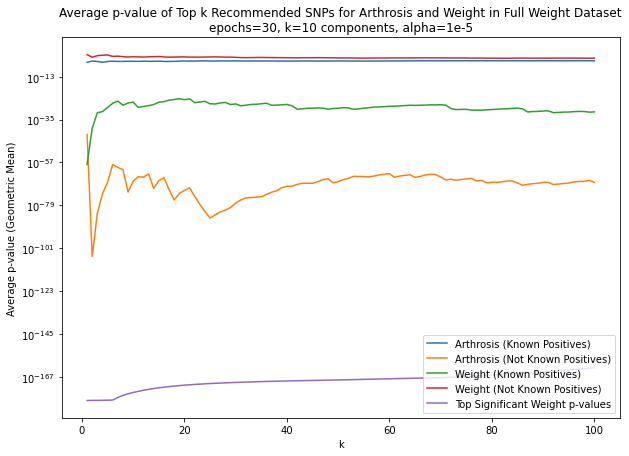

In [91]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')

plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_kp_weight)
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_weight)
plt.plot(range(1, 101), top_k_ave_pvals_weight_kp_weight)
plt.plot(range(1, 101), top_k_ave_pvals_weight_weight)
plt.plot(range(1, 101), top_k_ave_pvals_full_weight_data_first_100_pvalues)


plt.legend(['Arthrosis (Known Positives)', 'Arthrosis (Not Known Positives)', 'Weight (Known Positives)', 'Weight (Not Known Positives)', 'Top Significant Weight p-values'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Arthrosis and Weight in Full Weight Dataset\nepochs=30, k=10 components, alpha=1e-5')#gwas_model_e30_d10_reg00001

In [53]:
trait = '#Arthrosis'
return_list = []
n_traits, n_snps = data_e30_d10_reg00001['train'].shape
trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]
#SNPs known to relate to the trait
known_ranked_df = ts[(ts['Trait']==trait)].sort_values('pval_mlog', ascending=False)
known_ranked = list(known_ranked_df['snp_ind'])

known_ind = list(set(known_ranked))
ki_series = pd.Series(known_ind)

#SNPs model predicts that relate to trait
filtered_scores = gwas_model_e30_d10_reg00001.predict(trait_ind, np.array(known_ind))
#rank from most related to least
filtered_top_snps = [np.argsort(-filtered_scores)][0]
top_SNPs = ki_series[filtered_top_snps]

trait_list=[]
ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
df_first = df.groupby(by=['Reference SNP cluster ID']).first()
rec_s = list(ts_first.loc[list(top_SNPs)]['Reference SNP cluster ID'])
rec_chrom = list(df_first.loc[rec_s]['Chromosome'])
rec_p1 = list(df_first.loc[rec_s]['p1'])
rec_p2 = list(df_first.loc[rec_s]['p2'])
trait_list.append(rec_s)
trait_list.append(rec_chrom)
trait_list.append(rec_p1)
trait_list.append(rec_p2)
trait_list.append(list(np.array(filtered_scores)[filtered_top_snps]))
return_list.append(trait_list)
rec_info_arthrosis_kp = return_list

In [54]:
full_data_check_arthrosis_kp_arthrosis = check_full_data(arthrosis_df, rec_info_arthrosis_kp[0][0][:100])

100 matches


In [69]:
full_data_check_weight_kp_arthrosis = check_full_data(arthrosis_df, rec_info_weight_kp[0][0][:100])

100 matches


In [55]:
full_data_check_weight_arthrosis = check_full_data(arthrosis_df, rec_info_weight[0][0][:100])

100 matches


In [59]:
full_data_check_arthrosis_arthrosis = check_full_data(arthrosis_df, rec_info_arthrosis[0][0][:100])

100 matches


In [70]:
weight_arthrosis_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_arthrosis):
    weight_arthrosis_list.append(float(check[0][4]))
    
arthrosis_kp_arthrosis_list = []
for data, check in zip(rec_info_arthrosis_kp[0][0], full_data_check_arthrosis_kp_arthrosis):
    arthrosis_kp_arthrosis_list.append(float(check[0][4]))
    
arthrosis_arthrosis_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_arthrosis):
    arthrosis_arthrosis_list.append(float(check[0][4]))

weight_kp_arthrosis_list = []
for data, check in zip(rec_info_weight_kp[0][0], full_data_check_weight_kp_arthrosis):
    weight_kp_arthrosis_list.append(float(check[0][4]))

In [61]:
arthrosis_df['p-value'] = arthrosis_df['p-value'].astype(float)
full_arthrosis_data_first_100_pvalues = list(arthrosis_df.sort_values(['p-value'])['p-value'])[:100] 

In [71]:
top_k_ave_pvals_full_arthrosis_data_first_100_pvalues = top_k_ave_p(full_arthrosis_data_first_100_pvalues)
top_k_ave_pvals_arthrosis_arthrosis = top_k_ave_p(arthrosis_arthrosis_list)
top_k_ave_pvals_arthrosis_kp_arthrosis = top_k_ave_p(arthrosis_kp_arthrosis_list)
top_k_ave_pvals_weight_arthrosis = top_k_ave_p(weight_arthrosis_list)
top_k_ave_pvals_weight_kp_arthrosis = top_k_ave_p(weight_kp_arthrosis_list)

Text(0.5, 1.0, 'Average p-value of Top k Recommended SNPs for Arthrosis and Weight in Full Arthrosis Dataset\nepochs=30, k=10 components, alpha=1e-5')

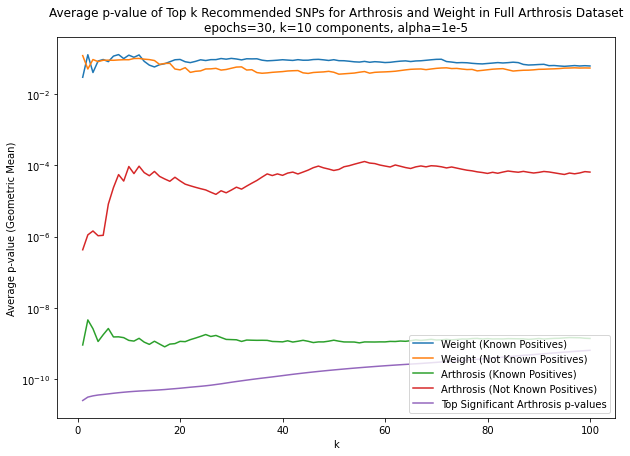

In [92]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')
plt.plot(range(1, 101), top_k_ave_pvals_weight_kp_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_weight_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_kp_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_full_arthrosis_data_first_100_pvalues)


plt.legend(['Weight (Known Positives)', 'Weight (Not Known Positives)', 'Arthrosis (Known Positives)', 'Arthrosis (Not Known Positives)', 'Top Significant Arthrosis p-values'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Arthrosis and Weight in Full Arthrosis Dataset\nepochs=30, k=10 components, alpha=1e-5')

In [139]:
#these snps exist in arthrosis recommendations but not in known positive weight recs
not_in_rec_info_weight_kp = ['rs7193038', 'rs13401333', 'rs13428823', 'rs73572177', 'rs6995407', 'rs12927052', 'rs12921407', 'rs7192213', 'rs8052225', 'rs12925429', 'rs8049373', 'rs11417831', 'rs4821741', 'rs6677960', 'rs73568154', 'rs12927168', 'rs8063226', 'rs59989839', 'rs1500337', 'rs3790078', 'rs6682581', 'rs8044876', 'rs2362642', 'rs12925700', 'rs11390043', 'rs12598642', 'rs555625140', 'rs6499263', 'rs2012725', 'rs552338537', 'rs881984', 'rs12926791', 'rs62027787', 'rs7526373', 'rs7569646', 'rs4373767', 'rs4146819', 'rs7563834', 'rs12919094', 'rs3790080', 'rs1466863', 'rs6720422', 'rs3762177', 'rs12446197', 'rs1561289', 'rs143311886', '6:98326220_GC_G', 'rs713468', 'rs9387823', 'rs7544369', 'rs7190013', 'rs1368740', 'rs4665766', 'rs12493461', 'rs6738297']

In [237]:
#looking into where the SNP recs for Arthrosis are located in the known positive recs for weight
#taking first 1100 SNPs
rec_info_arthrosis_SNP_ids_np = np.array(rec_info_arthrosis[0][0][:1100])
print(len(rec_info_arthrosis_SNP_ids_np))
not_in_rec_info_weight_kp_np = np.array(not_in_rec_info_weight_kp)
#removing SNPs from first 1000 arthrosis recs that do not exist in weight kp recs from arthrosis recs list
rec_info_arthrosis_SNP_ids_filtered = list(rec_info_arthrosis_SNP_ids_np[~np.isin(rec_info_arthrosis_SNP_ids_np, not_in_rec_info_weight_kp_np)])
print(len(rec_info_arthrosis_SNP_ids))
print(len(not_in_rec_info_weight_kp))
#finding rec position of SNPs recommended for arthrosis in list of weight recs
rec_info_arthrosis_SNP_ids_filtered = rec_info_arthrosis_SNP_ids_filtered[:1000]
rec_info_weight_kp_SNP_ids = rec_info_weight_kp[0][0]
rec_info_weight_kp_SNP_ids_df = pd.DataFrame(rec_info_weight_kp_SNP_ids, columns=['Reference SNP cluster ID'])
rec_info_weight_kp_SNP_ids_df['position'] = rec_info_weight_kp_SNP_ids_df.index
rec_info_weight_kp_SNP_ids_ser = rec_info_weight_kp_SNP_ids_df.set_index(['Reference SNP cluster ID'])['position']
position_arthrosis_recs_in_weight_kp_recs = list(rec_info_weight_kp_SNP_ids_ser[rec_info_arthrosis_SNP_ids_filtered])

1100
1000
55


In [203]:
rec_info_weight_kp_SNP_ids_ser['rs6088812']

8224

In [174]:
#verification
print(position_arthrosis_recs_in_weight_kp_recs[999])
print(rec_info_arthrosis_SNP_ids_filtered[999])
print(rec_info_weight_kp[0][0][4613])

4613
rs7238450
rs7238450


Text(0.5, 0.98, 'Comparing SNP Recommendation Positions for Arthrosis and Known Positive Weight Recommendations\nepochs=30, k=10 dimensions, a=1e-5')

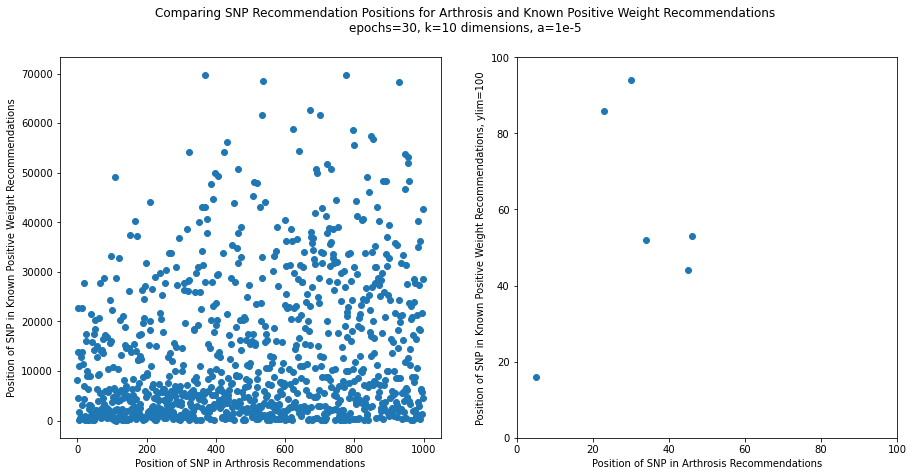

In [207]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15,7))
# fig = plt.figure(figsize=(12, 10))
fig.patch.set_facecolor('white')
ax1.scatter(range(len(position_arthrosis_recs_in_weight_kp_recs)), position_arthrosis_recs_in_weight_kp_recs)
ax2.scatter(range(len(position_arthrosis_recs_in_weight_kp_recs)), position_arthrosis_recs_in_weight_kp_recs)
ax2.set_ylim(0,100)
ax2.set_xlim(0,100)

# ax1.set_title('No ylim')
# ax2.set_title('ylim=2500')
ax1.set_xlabel('Position of SNP in Arthrosis Recommendations')
ax1.set_ylabel('Position of SNP in Known Positive Weight Recommendations')
ax2.set_xlabel('Position of SNP in Arthrosis Recommendations')
ax2.set_ylabel('Position of SNP in Known Positive Weight Recommendations, ylim=100')
fig.suptitle('Comparing SNP Recommendation Positions for Arthrosis and Known Positive Weight Recommendations\nepochs=30, k=10 dimensions, a=1e-5')

In [176]:
print(position_arthrosis_recs_in_weight_kp_recs.index(0))
print(rec_info_weight_kp[0][0][0])
print(rec_info_arthrosis_SNP_ids_filtered[111])

111
rs6785012
rs6785012


In [211]:
print(position_arthrosis_recs_in_weight_kp_recs.index(16))
print(rec_info_weight_kp[0][0][16])
print(rec_info_arthrosis[0][0][5])
print(full_data_check_weight_kp_weight[16])
print(full_data_check_arthrosis_weight[5])
print(weight_kp_weight_list[16])
print(arthrosis_weight_list[5])
first_100

5
rs66495454
rs66495454
[['chr1', '72282884', '72282885', 'rs66495454', '2.75208e-13']]
[['chr1', '72282884', '72282885', 'rs66495454', '2.75208e-13']]
2.75208e-13
2.75208e-13


array([ 8224,  4462, 22631, 13895, 10903,    16,  1690,   570,   234,
         396, 12900,   624, 13813,  3041, 22773, 11329,   445,   505,
        6879,  4334, 27840,   317,   885,    86,   302, 16050, 17544,
         336,  9907,  9027,    94,  6288,   541,  3087,    52,  2269,
        3217,  9077, 21561,  2966,  1196,  1247, 15896,  1229,   306,
          44,    53, 17407,   175, 14195, 20329,   577, 18429,  1012,
         827,  2175, 14967, 12772,  6352,  9273,  1739,  3966, 20763,
        9328,  2189,  5478, 27751, 13952,   451,  1369,   651, 14302,
        2553, 13645, 16527,  4619,  2101, 28792,  3370,  6021,  1158,
       17239,  2278,   974,   902,   441,  2456, 16842,  5828, 10402,
        2033,   753,  6375, 15720, 24224,  1708, 16139,   548, 33121,
        1047])

In [220]:
first_100 = position_arthrosis_recs_in_weight_kp_recs[:100]
first_100 = np.array(first_100)
rec_info_arthrosis_SNP_ids_filtered_np = np.array(rec_info_arthrosis_SNP_ids_filtered)
print(rec_info_arthrosis_SNP_ids_filtered_np[np.where(first_100<100)])
print(rec_info_weight_kp_SNP_ids_ser.iloc[first_100[np.where(first_100<100)]])
print(weight_df[weight_df['Reference SNP cluster ID']=='rs66495454'])
print()
print(weight_df[weight_df['Reference SNP cluster ID']=='rs7202116'])
print()
print(weight_df[weight_df['Reference SNP cluster ID']=='3:49959071_CT_C'])
print()
print(weight_df[weight_df['Reference SNP cluster ID']=='rs6749087'])
print()
print(weight_df[weight_df['Reference SNP cluster ID']=='rs13029479'])
print()
print(weight_df[weight_df['Reference SNP cluster ID']=='rs3101339'])

['rs66495454' 'rs7202116' '3:49959071_CT_C' 'rs6749087' 'rs13029479'
 'rs3101339']
Reference SNP cluster ID
rs66495454         16
rs7202116          86
3:49959071_CT_C    94
rs6749087          52
rs13029479         44
rs3101339          53
Name: position, dtype: int64
       Chromosome     Start       End Reference SNP cluster ID       p-value
327266       chr1  72282884  72282885               rs66495454  2.752080e-13

        Chromosome     Start       End Reference SNP cluster ID        p-value
4512634      chr16  53787703  53787704                rs7202116  7.477830e-168

        Chromosome     Start       End Reference SNP cluster ID       p-value
7824132       chr3  49921638  49921639          3:49959071_CT_C  2.372320e-29

        Chromosome   Start     End Reference SNP cluster ID       p-value
5778979       chr2  629818  629819                rs6749087  3.116530e-69

        Chromosome   Start     End Reference SNP cluster ID       p-value
5779247       chr2  655222  655223   

In [249]:
#setting up precision and recall calculations for arthrosis recs where positives = Known positive snps for weight
weight_kp_set = set(list(ts[ts['Trait']=='Weight']['Reference SNP cluster ID']))
arthrosis_recs_in_weight_kp_count = []
for i in rec_info_arthrosis[0][0]:
    if i in weight_kp_set:
        arthrosis_recs_in_weight_kp_count.append(1)
    else:
        arthrosis_recs_in_weight_kp_count.append(0)

In [248]:
k_vals = list(range(1, 1000))
k_vals.extend(list(np.arange(1000, len(rec_info_arthrosis[0][0]), 1000)))
print(len(k_vals))

3088


In [250]:
#calculating precision and recall for arthrosis recs where positives = Known positive snps for weight
arthrosis_recs_in_weight_kp_precision = []
arthrosis_recs_in_weight_kp_recall = []
total_sum = np.sum(arthrosis_recs_in_weight_kp_count)
for k in k_vals:
    count = np.sum(arthrosis_recs_in_weight_kp_count[:k])
    arthrosis_recs_in_weight_kp_precision.append(count/k)
    arthrosis_recs_in_weight_kp_recall.append(count/total_sum)

In [272]:
ts_traits_equal_arthrosis = ts[ts['Trait']=='#Arthrosis']
ts_traits_equal_weight = ts[ts['Trait']=='Weight']
ts_merged = ts_traits_equal_arthrosis.merge(ts_traits_equal_weight, left_on='Reference SNP cluster ID', right_on='Reference SNP cluster ID')
len(ts_merged)

19

In [274]:
len(ts_traits_equal_weight)-total_sum

19

Text(0.5, 1.0, 'Precision-Recall Curve for Arthrosis Recommendations where "Positives" are Known Positive SNPs for Weight\nepochs=30, k=10 components, alpha=1e-5')

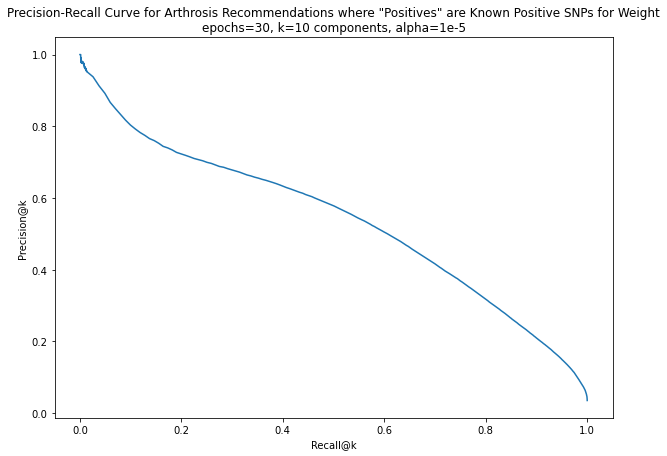

In [297]:
#Plot precision-recall curves for train and test data (1 epochs, 1 dimensions)
fig = plt.figure(figsize=(10,7))
fig.patch.set_facecolor('white')
plt.plot(arthrosis_recs_in_weight_kp_recall, arthrosis_recs_in_weight_kp_precision)
plt.xlabel('Recall@k')
plt.ylabel('Precision@k')
plt.title('Precision-Recall Curve for Arthrosis Recommendations where "Positives" are Known Positive SNPs for Weight\nepochs=30, k=10 components, alpha=1e-5')

**Looking at Printers known positives**

In [32]:
rec_info_printers = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Job SOC coding: Printers'], print_num=10)

Disease: Job SOC coding: Printers (1649)
   Known Positives (2308):
      Reference SNP cluster ID: rs142221565, chr3:69104483-69104484, p-value = 4.24538e-164
      Reference SNP cluster ID: rs150743530, chr3:69193651-69193652, p-value = 1.47383e-163
      Reference SNP cluster ID: rs529513858, chr2:32209554-32209555, p-value = 1.55027e-163
      Reference SNP cluster ID: rs79506707, chr11:6794934-6794935, p-value = 1.84679e-163
      Reference SNP cluster ID: rs182221550, chr18:62838830-62838831, p-value = 2.22561e-163
      Reference SNP cluster ID: rs182355775, chr2:73816829-73816830, p-value = 2.32349e-163
      Reference SNP cluster ID: rs113652317, chr2:73780092-73780093, p-value = 2.32349e-163
      Reference SNP cluster ID: rs111539317, chr2:73775051-73775052, p-value = 2.34247e-163
      Reference SNP cluster ID: rs147626836, chr2:73766413-73766414, p-value = 2.34247e-163
      Reference SNP cluster ID: rs140434296, chr11:6785459-6785460, p-value = 2.40960e-163
      ...

   

In [33]:
printers_df['p-value'] = printers_df['p-value'].astype(float)
printers_df.sort_values('p-value')

,Chromosome,Start,End,Reference SNP cluster ID,p-value
7918796,chr3,69104483,69104484,rs142221565,4.245380e-164
7919300,chr3,69193651,69193652,rs150743530,1.473830e-163
5938939,chr2,32209554,32209555,rs529513858,1.550270e-163
1766749,chr11,6794934,6794935,rs79506707,1.846790e-163
5368992,chr18,62838830,62838831,rs182221550,2.225610e-163
...,...,...,...,...,...
13767910,chrX,148024871,148024872,rs138961586,NaN
13784908,chrX,153864647,153864648,rs782260124,NaN
13786001,chrX,154461419,154461420,rs145615075,NaN
13786047,chrX,154478417,154478418,rs782786534,NaN


**Looking into if the recs for a given trait are next in line in the full dataset**

In [34]:
rec_info = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['#Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers'], print_num=1)
rec_info_arthrosis_SNPs = rec_info[0][0]
rec_info_melanoma_SNPs = rec_info[1][0]
rec_info_weight_SNPs = rec_info[2][0]
rec_info_sra_SNPs = rec_info[3][0]
rec_info_printers_SNPs = rec_info[4][0]

Disease: #Arthrosis (0)
   Known Positives (237):
      Reference SNP cluster ID: rs559230165, chr1:219580670-219580671, p-value = 2.51849e-11
      ...

   Recommended:
      Reference SNP cluster ID: rs6088812, chr20:35386360-35386361
Disease: Malignant melanoma of skin (2108)
   Known Positives (1801):
      Reference SNP cluster ID: rs201432166, chr1:176699286-176699287, p-value = 1.14919e-50
      ...

   Recommended:
      Reference SNP cluster ID: rs371089226, chr22:38599874-38599875
Disease: Weight (3744)
   Known Positives (72606):
      Reference SNP cluster ID: rs11642015, chr16:53768582-53768583, p-value = 1.14192e-191
      ...

   Recommended:
      Reference SNP cluster ID: rs10840357, chr11:10069431-10069432
Disease: Seropositive rheumatoid arthritis (2888)
   Known Positives (4459):
      Reference SNP cluster ID: rs374013240, chr22:38638800-38638801, p-value = 1.61150e-242
      ...

   Recommended:
      Reference SNP cluster ID: rs9273391, chr6:32659266-32659267
Dis

In [305]:
trait_names = ['arthrosis', 'melanoma', 'weight', 'sero_rheuma_arthritis', 'printers']
traits = ['#Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers']

In [36]:
pickle_out_recs = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_reg00001_rec_info_arthrosis_melanoma_weight_sra_printers.pickle', 'wb')
pickle.dump(rec_info, pickle_out_recs)
pickle_out_recs.close()

In [321]:
pickle_in = open('/home/ctrader/Hold/GWAS/gwas_model_e30_d10_reg00001_rec_info_arthrosis_melanoma_weight_sra_printers.pickle', 'rb')
rec_info=pickle.load(pickle_in)
rec_info_arthrosis_SNPs = rec_info[0][0]
rec_info_melanoma_SNPs = rec_info[1][0]
rec_info_weight_SNPs = rec_info[2][0]
rec_info_sra_SNPs = rec_info[3][0]
rec_info_printers_SNPs = rec_info[4][0]

In [345]:
#takes in dataframe of all known associations with trait of interest and a list of SNPs. Returns a 
#list of associations found between the trait and the given SNPs. 
def check_full_data_2(full_data, snp_recs):
    full_data_ser = full_data.set_index('Reference SNP cluster ID')['p-value']
    ordered_pvals = full_data_ser[snp_recs]
    return ordered_pvals

In [347]:
full_data_check_arthrosis_10000 = list(check_full_data_2(arthrosis_df, rec_info_arthrosis_SNPs[:10000]))
full_data_check_melanoma_10000 = list(check_full_data_2(melanoma_skin_df, rec_info_melanoma_SNPs[:10000]))
full_data_check_weight_10000 = list(check_full_data_2(weight_df, rec_info_weight_SNPs[:10000]))
full_data_check_sra_10000 = list(check_full_data_2(rheu_seropos_df, rec_info_sra_SNPs[:10000]))
full_data_check_printers_10000 = list(check_full_data_2(printers_df, rec_info_printers_SNPs[:10000]))

In [359]:
full_data_check_2_pvals = [full_data_check_arthrosis_10000, full_data_check_melanoma_10000, full_data_check_weight_10000, full_data_check_sra_10000, full_data_check_printers_10000]

In [364]:
#saving recs as bed files for iceberg plots
today = date.today()
for j in range(len(traits)):
    bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_rec_info_' + trait_names[j] + '_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(10000):
        f.write(rec_info[j][1][i] + '\t' + str(rec_info[j][2][i]) + '\t' + str(rec_info[j][3][i]) + '\t' + str(rec_info[j][4][i]) + '\t' + str(rec_info[j][0][i]) + '\t' + str(full_data_check_2_pvals[j][i]) + '\n')
    f.close()

In [302]:
#Arthrosis
arthrosis_df['p-value'] = arthrosis_df['p-value'].astype(float)
arthrosis_df = arthrosis_df.sort_values('p-value')
arthrosis_df_non_significant = arthrosis_df[arthrosis_df['p-value']>5e-8]
arthrosis_df_non_significant = arthrosis_df_non_significant.reset_index()
arthrosis_df_non_significant['index'] = arthrosis_df_non_significant.index
arthrosis_df_non_significant = arthrosis_df_non_significant.set_index(['Reference SNP cluster ID'])
arthrosis_df_non_significant_ser = arthrosis_df_non_significant['index']
non_significant_arthrosis_recs_position = list(arthrosis_df_non_significant_ser[rec_info_arthrosis_SNPs])

In [38]:
#Malignant melanoma of the skin
melanoma_skin_df['p-value'] = melanoma_skin_df['p-value'].astype(float)
melanoma_skin_df = melanoma_skin_df.sort_values('p-value')
melanoma_skin_df_non_significant = melanoma_skin_df[melanoma_skin_df['p-value']>5e-8]
melanoma_skin_df_non_significant = melanoma_skin_df_non_significant.reset_index()
melanoma_skin_df_non_significant['index'] = melanoma_skin_df_non_significant.index
melanoma_skin_df_non_significant = melanoma_skin_df_non_significant.set_index(['Reference SNP cluster ID'])
melanoma_skin_df_non_significant_ser = melanoma_skin_df_non_significant['index']
non_significant_melanoma_recs_position = list(melanoma_skin_df_non_significant_ser[rec_info_melanoma_SNPs])

In [39]:
#Weight
weight_df['p-value'] = weight_df['p-value'].astype(float)
weight_df = weight_df.sort_values('p-value')
weight_df_non_significant = weight_df[weight_df['p-value']>5e-8]
weight_df_non_significant = weight_df_non_significant.reset_index()
weight_df_non_significant['index'] = weight_df_non_significant.index
weight_df_non_significant = weight_df_non_significant.set_index(['Reference SNP cluster ID'])
weight_df_non_significant_ser = weight_df_non_significant['index']
#these two SNPs do not exist in full dataset
rec_info_weight_SNPs.remove('rs370681036')
rec_info_weight_SNPs.remove('rs190413347')
non_significant_weight_recs_position = list(weight_df_non_significant_ser[rec_info_weight_SNPs])

In [40]:
#Seropositive rheumatoid arthritis
rheu_seropos_df['p-value'] = rheu_seropos_df['p-value'].astype(float)
rheu_seropos_df = rheu_seropos_df.sort_values('p-value')
rheu_seropos_df_non_significant = rheu_seropos_df[rheu_seropos_df['p-value']>5e-8]
rheu_seropos_df_non_significant = rheu_seropos_df_non_significant.reset_index()
rheu_seropos_df_non_significant['index'] = rheu_seropos_df_non_significant.index
rheu_seropos_df_non_significant = rheu_seropos_df_non_significant.set_index(['Reference SNP cluster ID'])
rheu_seropos_df_non_significant_ser = rheu_seropos_df_non_significant['index']
non_significant_rheu_seropos_recs_position = list(rheu_seropos_df_non_significant_ser[rec_info_sra_SNPs])

In [41]:
not_in_printers_non_significant_full_data = ['rs77815840', 'rs201447515', 'rs563719782', 'rs368625295', 'rs539769126', 'rs147221532', 'rs546077003', 'rs151260103', 'rs530416232', 'rs140519341', 'rs104895430', 'rs555980638', 'rs148100123', 'rs148497570', 'rs185114210', 'rs188571773', 'rs540591044', 'rs576303490', 'rs553708686', 'rs547824816', 'rs201880929', 'rs373998853', 'rs114556043', 'rs201081714', 'rs537630641', 'rs139804478', 'rs116420052', 'rs201469408', 'rs147622465', 'rs6716782', 'rs529871486', 'Affx-89008190', 'rs369544043', 'rs140341744', 'rs151287310', 'rs149699425', 'rs150580252', 'rs72931627', 'rs151021379', 'rs148631523', 'rs200858786', 'rs61734960', 'rs537335234', 'rs557282296', 'rs2229107', 'rs12242384', 'rs199531593', 'rs143088014', 'rs201938176', 'rs56737889', 'rs577545383', 'rs150527574', 'rs373859283', 'rs137908658', 'rs61751154', 'rs199997948', 'rs149696931', 'rs200024416', 'rs150727372', 'rs34824876', 'rs147573752', 'rs149500485', 'rs140228766', 'rs200625438', 'rs192965228', 'rs111572553', 'rs202105292', 'rs148432146', 'rs376632669', 'rs55872061', 'rs530800595', 'rs376005400', 'rs565400729', 'rs530733277', 'rs138659144', 'rs183862699', 'rs542993646', 'rs148365707', 'rs561562230', 'rs115232659', 'rs145342112', 'rs77054338', 'rs547900184', 'rs191728325', 'rs75589461', 'rs147746065', 'rs192996860', 'rs573471533', 'rs61735520', 'rs563363846', 'rs60180055', 'rs201845569', 'rs141168573', 'rs114840330', 'rs41313031', 'rs140145107', 'rs545371063', 'rs546124449', 'rs141933761', 'rs143945485', 'rs149572207', 'rs544368328', 'rs143560777', 'rs148409263', 'rs138524298', 'rs535257518', 'rs574889711', 'rs567697961', 'rs369362135', 'rs142716458', 'rs115322542', 'rs146642388', 'rs141355470', 'rs149689401', 'rs145906734', 'rs538106019', 'rs137998120', 'rs142336603', 'rs550861405', 'rs145130069', 'rs200634890', 'rs7262873', 'rs61740627', 'rs563417218', 'rs374025310', 'rs540565978', 'rs200528144', 'rs145678669', 'rs139808535', 'rs142225522', 'rs559151727', 'rs147497475', 'rs145329488', 'rs186282504', 'rs148302547', 'rs144135379', 'rs570566550', 'rs142271678', 'rs556474084', 'rs368042301', 'rs190602542', 'rs112315516', 'rs182857825', 'rs142540692', 'rs76985854', 'rs564362481', 'rs530773745', 'rs141451008', 'rs564905233', 'rs187627402', 'rs561071711', 'rs542759861', 'rs185704507', 'rs139940282', 'rs61733022', 'rs144946747', 'rs138645358', 'rs142256935', 'rs2845563', 'rs185019136', 'rs556531467', 'rs555395531', 'rs144743183', 'rs539675158', 'rs543724783', 'rs140513282', 'rs148105276', 'rs61731722', 'rs148874863', 'rs201116726', 'rs148348903', 'rs148463763', 'rs61750625', 'rs561675338', 'rs142548792', 'rs115379999', 'rs57750167', 'rs144024361', 'rs533020242', 'rs147011033', 'rs2296651', 'rs185142903', 'rs148576098', 'rs34854792', 'rs113062643', 'rs181938117', 'rs144168661', 'rs374426095', 'rs17884957', 'rs191753687', 'rs199672137', 'rs142257239', 'rs111441932', 'rs139674390', 'rs138787768', 'rs556307695', 'rs544624379', 'rs561882274', 'rs372529845', 'rs200519273', 'rs150127553', 'rs114536874', 'rs200262580', 'rs112954305', 'rs587595911', 'rs143564151', 'rs201270462', 'rs368953418', 'rs142708410', 'rs551421793', 'rs531082359', 'rs140072002', 'rs186244950', 'rs573094394', 'rs200750351', 'rs193164370', 'rs201023213', 'rs151173074', 'rs76710074', 'rs545371945', 'rs35720727', 'rs578154613', 'rs563171879', 'rs377554974', 'rs17222632', 'rs139560074', 'rs144514511', 'rs143406914', 'rs11541541', 'rs35339236', 'rs369656195', 'rs185710659', 'rs533945076', 'rs200350605', 'rs575983394', 'rs377135624', 'rs201178550', 'rs143156281', 'rs546759760', 'rs532344850', 'rs201350340', 'rs201925617', 'rs150595875', 'rs139283268', 'rs17885655', 'rs146242609', 'rs146184522', 'rs144614902', 'rs114463099', 'rs186942770', 'rs551797269', 'rs201270274', 'rs200584784', 'rs188733917', 'rs571863743', 'rs140507994', 'rs199543162', '19:58363718_TG_T', 'rs143338649', 'rs201714190', 'rs149181442', 'rs374744704', 'rs138612527', 'rs144536215', 'rs374769239', 'rs3213173', 'rs147993981', 'rs577344713', 'rs534737466', 'rs148541483', 'rs114108445', 'rs145492156', 'rs111726902', 'rs554100812', 'rs201169452', 'rs533692248', 'rs542299684', 'rs147406105', 'rs137945646', 'rs564744260', '9:140325685_T_G', 'rs115096288', 'rs201173138', 'rs189246389', 'rs202107729', 'rs558641758', 'rs200102494', 'rs77984885', 'rs564653772', 'rs201768717', 'rs147284380', 'rs537876996', 'rs138771137', 'rs142816072', 'rs111749614', 'rs138477419', 'rs112181735', 'rs143568996', 'rs150407754', 'rs552756954', 'rs145519146', '9:140196334_C_A', 'rs138087514', 'rs146834034', 'rs201653433', 'rs144724549', 'rs548158408', '9:140328773_C_T', 'rs377732143', 'rs148327567', 'rs201539021', 'rs372440713', 'rs181020996', 'rs554920046', 'rs372611802', 'rs185393063', 'rs372309426', 'rs531793725', 'rs150055938', 'rs56391084', 'rs370457949', 'rs72999042', 'rs7128237', 'rs544106020', '19:58102635_AAC_A', 'rs199793257', 'rs371819463', 'rs372930527', 'rs2228271', 'rs144694933', 'rs149658464', 'rs200383612', 'rs144507273', 'rs541244427', 'rs375679720', 'rs200530619', 'rs138799538', 'rs200759347', 'rs147122911', 'rs180969361', 'rs145803209', 'rs531746754', 'rs149174692', 'rs570571625', 'rs563372059', 'rs556768733', 'rs116815894', 'rs538127489', 'rs371623584', 'rs200532772', 'rs201039935', 'rs575596742', 'rs529125628', 'rs149060494', 'rs111883392', 'rs146423675', 'rs200002676', 'rs558490742', 'rs140988229', 'rs150682094', 'rs148873732', 'rs199676790', 'rs534197455', 'rs137909519', 'rs567605468', 'rs147461403', 'rs143087318', 'rs368913580', 'rs73394756', 'rs551459565', 'rs142173097', 'rs151213644', 'rs144905283', 'rs76300532', 'rs114232288', 'rs2069380', 'rs150246562', 'rs576239233', 'rs189728809', 'rs143528608', 'rs571350661', 'rs143191258', 'rs116615990', 'rs202155357', 'rs568451027', 'rs200004303', 'rs199776201', 'rs143610596', 'rs138968424', 'rs537538033', 'rs371544634', 'rs575568934', 'rs11567962', 'rs553354514', 'rs532318094', 'rs569453359', 'rs552056481', 'rs561949979', 'rs574994287', 'rs74482326', 'rs12948434', 'rs552234260', 'rs141369006', 'rs140575096', 'rs550459981', 'rs78479224', 'rs370218166', 'rs147657405', 'rs150533375', 'rs147045782', 'rs572784064', 'rs554052175', 'rs138583401', 'rs571125128', 'rs568977268', 'rs143889768', 'rs374249911', 'rs114604356', 'rs147563485', 'rs151336429', 'rs151311268', 'rs200869545', 'rs536285042', 'rs527661866', 'rs112600680', 'rs145763601', 'rs200868600', '16:1271793_CAG_C', 'rs139679398', 'rs374231043', 'rs147930036', 'rs138168899', 'rs143969346', 'rs369899875', 'rs189594633', 'rs200569240', 'rs148457506', 'rs371522346', 'rs202096200', 'rs147984058', 'rs545917447', 'rs115374113', 'rs138259370', 'rs142051981', 'rs577400119', 'rs142884205', 'rs530601467', 'rs188404201', 'rs199885473', 'rs185552042', 'rs574384512', 'rs182346627', 'rs538772421', 'rs571259684', 'rs374080396', 'rs150461450', 'rs201776658', 'rs144683695', 'rs541454235', 'rs574789930', 'rs147165460', 'rs182319199', 'rs534523640', 'rs201875004', 'rs149266584', 'rs148922231', 'rs573299122', 'rs149693931', 'rs559471279', 'rs144489730', 'rs201505794', 'rs149887215', 'rs139459760', 'rs199934829', 'rs200172336', 'rs545343442', 'rs570645003', 'rs538270912', 'rs144079786', 'rs200344313', 'rs201395805', 'rs551660149', 'rs138979270', 'rs140218299', 'rs543314513', 'rs5744016', 'rs78311619', 'rs539305564', 'rs145190151', 'rs373988845', 'rs142782886', 'rs189232206', 'rs144679421', 'rs114495250', '9:140130396_G_A', 'rs145097656', 'rs369272246', 'rs576374556', 'rs61737888', 'rs564430878', 'rs141880507', 'rs11573598', 'rs199500373', 'rs149096573', 'rs371612347', 'rs34881036', 'rs141281478', 'rs191225974', 'rs112672659', 'rs141175381', 'rs150035089', 'rs148937367', 'rs187492325', 'rs182108836', 'rs547400718', 'rs370278031', 'rs144160852', 'rs115367873', 'rs184914524', 'rs565831375', 'rs186005100', 'rs201778703', 'rs549653182', 'rs142799522', 'rs144415810', 'rs555225002', 'rs73993548', 'rs145881911', 'rs149447818', 'rs140012085', 'rs143798431', 'rs533208137', 'rs148162251', 'rs201307934', 'rs551154538', 'rs199934247', 'rs189041235', 'rs146316052', 'rs201354562', 'rs575878889', 'rs150271208', 'rs530675894', 'rs373496180', 'rs138709216', 'rs199536909', 'rs369000213', 'rs543350729', 'rs200310087', 'rs142667188', 'rs143958148', 'rs192496216', 'rs139576513', 'rs147342829', 'rs531060384', 'rs115891498', 'rs142118461', 'rs139111190', 'rs140811480', 'rs77373295', 'rs143643360', 'rs182292920', 'rs562038092', 'rs368050604', 'rs141027782', 'rs567036234', 'rs575270915', 'rs147527758', 'rs140102475', 'rs531889326', '1:100626086_AGCTTGGT_A', 'rs141505678', 'rs377096813', 'rs200034773', 'rs141622697', 'rs371250005', 'rs145415310', 'rs140736445', 'rs371409662', 'rs553611640', 'rs145897230', 'rs573490046', 'rs76702938', 'rs571158691', 'rs146006151', 'rs557485083', 'rs367627396', 'rs193141134', 'rs557007416', 'rs191426106', 'rs141858181', 'rs187005190', 'rs181299906', 'rs145028680', 'rs202238258', 'rs201550948', 'rs376564487', 'rs3917429', 'rs199849336', 'rs35304756', 'rs79737608', 'rs77807333', 'rs151006917', 'rs147826913', 'rs552336969', 'rs34423210', 'rs371793819', 'rs547402777', 'rs554664280', 'rs141303233', 'rs142671314', 'rs34830712', 'rs201685421', 'rs116100727', 'rs34938201', 'rs57831260', 'rs201343502', 'rs192902075', 'rs140110202', 'rs4687793', 'rs202020703', 'rs192758588', 'rs186879295', 'rs61746364', 'rs566292000', 'rs142446757', 'rs75275319', '19:22940283_TTA_T', 'rs567716838', 'rs577303851', 'rs183792404', 'rs139143750', 'rs142369909', 'rs201720265', 'rs549374828', 'rs149445499', 'rs144937311', 'rs549493357', '9:140161737_C_T', 'rs545711298', 'rs181287620', 'rs139570211', '9:140115490_T_C', 'rs181529013', 'rs142872154', 'rs536559356', 'rs147658647', 'rs556014868', 'rs200551058', 'rs587652432', '9:35042932_GGAA_G', 'rs372513856', 'rs144377641', 'rs557412818', 'rs17184058', 'rs201775541', 'rs190978463', 'rs148930323', 'rs375439571', 'rs144269892', 'rs186054834', 'rs141383610', 'rs116197390', 'rs150831986', 'rs147673427', 'rs140575323', 'rs539762304', 'rs551933531', 'rs139388902', 'rs140664272', 'rs568567404', 'rs373784874', 'rs532234553', 'rs547803731', 'rs143883022', 'rs201846479', 'rs554680182', 'rs200272917', 'rs143293913', 'rs147087175', 'rs146616455', 'rs537795646', 'rs554835653', 'rs147419502', 'rs144827029', 'rs12091253', 'rs183644163', 'rs532463670', 'rs547551060', 'rs200074466', 'rs5998104', 'rs139329569', 'rs146153632', 'rs369961373', 'rs142902034', 'rs377716669', 'rs375056876', '9:140327689_C_G', 'rs149333067', 'rs111556626', 'rs140620720', 'rs140405180', 'rs201400073', '9:140318119_C_G', 'rs140417509', 'rs150056369', 'rs143615169', 'rs568767393', 'rs142997689', 'rs534326950', 'rs113208516', 'rs547001287', 'rs372593602', 'rs141344505', 'rs138592405', 'rs149711534', 'rs570060177', 'rs148519764', 'rs142060431', 'rs375641145', '9:140109389_G_A', 'rs201586656', 'rs78840700', 'rs369681198', 'rs533329297', 'rs372292959', 'rs140123211', 'rs572555898', 'rs116099947', 'rs146308829', 'rs200364798', 'rs200396163', 'rs142386076', 'rs139085745', 'rs150442838', 'rs571910239', 'rs200565505', 'rs147528900', 'rs565872876', 'rs147795840', 'rs371110390', 'rs542317875', 'rs374443913', 'rs564383457', 'rs569192492', 'rs374380028', 'rs148599494', 'rs376717625', 'rs535384375', 'rs367585089', 'rs144244281', '9:140128869_C_T', 'rs374709745', 'rs202039431', 'rs532001593', 'rs201992648', 'rs199721558', 'rs146343935', 'rs376434225', 'rs371162432', 'rs147095072', 'rs113146258', 'rs34928488', 'rs114079678', 'rs146285395', 'rs528479579', 'rs142608987', 'rs140297311', 'rs183047238', 'rs548206510', 'rs576527377', 'rs143602361', 'rs145268174', 'rs548351594', 'rs782260124', 'rs375221971', 'rs201524664', 'rs553617422', '9:140329525_G_C', 'rs77624079', 'rs5495', 'rs144919589', 'rs144070983', 'rs150120079', 'rs116203266', 'rs545486754', 'rs368128716', 'rs182392430', 'rs138578392', 'rs367759946', 'rs529543552', 'rs140591945', 'rs372158302', 'rs151187593', 'rs535599077', 'rs113155109', '9:140275706_T_C', 'rs151202823', 'rs116454042', 'rs111604607', 'rs141954373', 'rs73903305', 'rs564131660', 'rs564577177', 'rs571097830', 'rs369124503', 'rs116689515', 'rs782433303', 'rs574255794', 'rs143691635', 'rs199691660', 'rs147397431', 'rs61736435', 'rs140668639', 'rs373354080', 'rs35859404', 'rs144913308', 'rs200855969', 'rs140011802', 'rs559407977', 'rs531665453', 'rs782786534', 'rs372573622', 'rs148189817', 'rs547040339', 'rs146151791', 'rs569901358', 'rs201271231', 'rs143576513', 'rs146612508', 'rs35956512', 'rs556525831', 'rs143709902', 'rs540822809', '9:140248093_T_C', 'rs151149571', 'rs144269675', 'rs371268059', 'rs111624269', 'rs141882356', 'rs138423168', 'rs532062661', 'rs150470720', 'rs144635426', 'rs115290230', 'rs536672128', 'rs150341657', 'rs200561999', 'rs150795053', 'rs547123940', 'rs374419129', 'rs200065471', 'rs573681049', 'rs145670920', 'rs577356066', 'rs550094832', 'rs528017917', '9:140147162_G_T', 'rs552525010', 'rs145553596', 'rs536958788', 'rs199806972', 'rs148148316', 'rs201487340', 'rs545234511', 'rs144356897', 'rs201746064', 'rs559032408', 'rs143826988', 'rs553023026', 'rs147743758', '9:140249179_C_T', 'rs199717141', 'rs372838090', 'rs141405955', 'rs185219431', 'rs190099155', 'rs374458508', 'rs148430364', 'rs191045080', 'rs182899853', 'rs11539315', 'rs191555811', 'rs556905949', 'rs141332149', 'rs370229164', 'rs113067656', 'rs145855772', 'rs529785223', 'rs150427929', 'rs537666246', 'rs151058774', 'rs538572804', 'rs147705566', 'rs35264841', 'rs201820631', 'rs139541328', 'rs558959240', 'rs115901579', 'rs557509141', 'rs147477038', 'rs199655307', 'rs543164039', 'rs576103445', 'rs529241246', 'rs142217560', 'rs149490522', 'rs189194995', 'rs558581290', 'rs549953294', 'rs563847398', 'rs146731847', 'rs578152892', 'rs536001903', 'rs147548483', 'rs150066085', 'rs114352644', 'rs148595313', 'rs554984029', 'rs552738008', 'rs569878094', 'rs139909751', 'rs147659527', 'rs557427501', 'rs372345016', 'rs112973322', 'rs144494381', 'rs149415462', 'rs369898187', 'rs369529123', 'rs141567487', 'rs549005226', 'rs75030364', 'rs199994194', 'rs114896365', 'rs557098303', 'rs34704994', 'rs182090249', 'rs189625777', 'rs148363571', 'rs587711475', 'rs1521808', 'rs375042715', 'rs115409230', 'rs376359607', 'rs141969833', 'rs202053684', 'rs116121199', 'rs61736853', 'rs368075131', 'rs371316448', 'rs148012547', 'rs201232069', 'rs188876807', 'rs548384931', 'rs142844253', 'rs146946903', 'rs557308545', 'rs367890582', 'rs538319943', 'rs200684774', 'rs558188212', 'rs147711327', 'rs149495960', 'rs11544785', 'rs574456869', 'rs141504927', 'rs368660628', 'rs574569918', 'rs370634086', 'rs73488045', 'rs143938374', 'rs115595651', 'rs149349311', 'rs377173655', 'rs374773665', 'rs572091188', 'rs138192696', 'rs146777193', 'rs148025735', 'rs188813129', 'rs61747624', 'rs546002277', 'rs74317435', 'rs782075305', 'rs7696137', 'rs184880771', 'rs559883981', 'rs367944926', 'rs560016001', 'rs201616041', 'rs199906600', 'rs149703831', 'rs373127897', 'rs143236717', 'rs61733021', 'rs568397466', 'rs200313531', 'rs533890042', 'rs375986462', 'rs61733883', 'rs549565879', 'rs193126290', 'rs559624894', 'rs142219494', 'rs200243170', 'rs190197851', 'rs144661928', 'rs186121995', 'rs149414821', 'rs146046908', 'rs539557197', 'rs147452733', 'rs184278314', 'rs534376494', 'rs551406327', 'rs145359827', 'rs140470940', 'rs536204949', 'rs112117118', 'rs530468968', 'rs199615908', 'rs143513641', 'rs146485772', 'rs150800052', '9:140330987_C_T', 'rs113096800', 'rs372437635', 'rs577596223', 'rs535811260', 'rs201747594', 'rs146175770', 'rs189006246', 'rs549497811', 'rs113806212', 'rs150920213', 'rs201797109', 'rs112960305', 'rs570457132', 'rs148932387', 'rs563022985', 'rs148848526', 'rs201873954', 'rs372733155', 'rs202003275', 'rs143515757', 'rs112853298', 'rs200916097', 'rs369516328', 'rs190072564', 'rs371089226', 'rs545474995', 'rs200431441', 'rs146744453', 'rs114079572', 'rs182840438', 'rs5005771', 'rs368232843', 'rs145486377', 'rs553391207', 'rs199562757', 'rs141959251', 'rs373923523', 'rs16945946', 'rs140664656', 'rs202108516', 'rs143647342', 'rs188057660', 'rs74457909', 'rs372223602', 'rs139331110', 'rs556841355', 'rs186829304', 'rs55643406', 'rs74430256', 'rs138232522', 'rs74428123', 'rs548384070', 'rs186938508', '9:140087043_TCC_T', 'rs36052446', 'rs200200777', 'rs558226618', 'rs576954151', '9:140139656_C_T', 'rs375121850', 'rs144260319', 'rs145963430', 'rs141399202', 'rs150716378', 'rs535282575', 'rs116306564', 'rs548675904', 'rs192536821', 'rs187912240', 'rs115895016', 'rs149392380', 'rs530004450', 'rs369694814', 'rs542337660', 'rs147612932', 'rs149886485', 'rs142984971', 'rs77515942', 'rs558668826', 'rs143801580', 'rs182335661', 'rs370422239', 'rs76774578', 'rs557365474', 'rs144924394', 'rs560660167', 'rs541848444', 'rs191694871', 'rs566306688', 'rs112756835', 'rs375319088', 'rs180684648', 'rs201372955', 'rs571078087', 'rs549662786', 'rs184026566', 'rs78427006', 'rs368864321', 'rs563130958', 'rs114799698', 'rs112991946', 'rs142874874', 'rs138555701', 'rs184433622', 'rs75507283', 'rs143930780', 'rs147052074', 'rs201980498', 'rs143029667', 'rs186648174', 'rs374860840', 'rs528306964', 'rs374606822', 'rs141978579', 'rs569596497', 'rs370199297', 'rs150481557', 'rs569902822', 'rs568493483', 'rs533329793', 'rs564770593', 'rs147861149', 'rs201942688', 'rs569918568', 'rs17512877', 'rs116496912', 'rs146609079', 'rs562685455', 'rs566740788', 'rs150552076', 'rs147214175', '5:143757429_TTAGG_T', 'rs138677083', 'rs536931928', 'rs183001288', 'rs138635982', 'rs144662796', 'rs369417256', 'rs574794395', 'rs141377590', 'rs140332206', 'rs144234953', 'rs199909827', 'rs149721540', 'rs143518519', 'rs546842447', 'rs368807340', 'rs199615475', 'rs77963070', 'rs201648021', 'rs572402483', 'rs184758846', 'rs577626424', 'rs373674546', 'rs144441692', 'rs181566863', 'rs575456303', '9:140115257_C_A', 'rs35479032', 'rs186603174', 'rs7038451', 'rs142005186', 'rs145425294', 'rs140658331', 'rs201429460', 'rs567799767', 'rs544439135', 'rs61744574', 'rs144744180', 'rs150455097', 'rs569953104', 'rs373257450', 'rs566846367', 'rs201686460', 'rs374962575', 'rs145889610', 'rs138450053', 'rs114369311', 'rs543035977', 'rs79556800', 'rs368852045', 'rs202192406', 'rs141463671', 'rs543384323', 'rs151335104', 'rs150582291', 'rs190704778', 'rs373993220', 'rs147595873', 'rs187290995', 'rs200235342', 'rs551932836', 'rs76829163', 'rs377283955', 'rs547589952', 'rs377272529', 'rs560379786', 'rs139033408', 'rs146138646', 'rs544405143', 'rs143016806', 'rs555860663', 'rs147731637', 'rs536653446', 'rs191203557', 'rs553841906', 'rs529196333', 'rs372014231', 'rs548743423', 'rs561439651', 'rs540763634', 'rs147192886', 'rs201555141', 'rs532019224', 'rs375565374', 'rs368700420', 'rs138945081', 'rs554390480', 'rs372159380', 'rs541421744', 'rs557960190', 'rs532329476', 'rs554480269', 'rs73779542', 'rs140567712', 'rs546137847', 'rs200424451', 'rs370856154', 'rs569410899', 'rs182443406', 'rs11964847', 'rs371081137', 'rs139796030', 'rs150297508', 'rs147319497', 'rs35481467', 'rs34589480', 'rs376229752', 'rs372512148', 'rs144334321', 'rs202217070', 'rs144415900', 'rs374372464', 'rs140117865', 'rs375960143', 'rs141087114', 'rs34878592', 'rs376141767', 'rs112488180', 'rs143760165', 'rs550194728', 'rs375647301', 'rs149895631', 'rs576382288', 'rs554298331', 'rs200671433', 'rs199814928', 'rs187482608', 'rs150469831', 'rs373941516', 'rs540490736', 'rs541625725', 'rs201128714', 'rs563910734', 'rs147564718', 'Affx-52357858', 'rs190283462', 'rs141615393', 'rs149237231', 'rs181398214', 'rs80333749', 'rs140740176', 'rs192699400', 'rs149630750', 'rs548123734', 'rs201341174', 'rs201200405', 'rs539318764', '9:140130552_G_C', 'rs200878416', 'rs573591955', 'rs116704384', 'rs374576199', 'rs138689793', 'rs548726318', 'rs61746426', 'rs140460455', 'rs370336923', '9:140355171_G_A', 'rs138961586', 'rs61746437', 'rs561821620', 'rs376590878', 'rs111480507', 'rs369761537', 'rs543279513', 'rs114920421', 'rs373875040', 'rs188808287', 'rs200324593', 'rs540271797', 'rs554587235', 'rs113540514', '9:140328470_C_T', 'rs536327712', 'rs184528421', 'rs185154955', 'rs74977190', 'rs567187570', 'rs535191163', 'rs150429752', 'rs199527614', 'rs201689055', 'rs201758107', 'rs145441025', 'rs146729116', 'rs147525649', 'rs533396391', 'rs554608206', 'rs36051967', 'rs148810189', 'rs201692012', 'rs151229275', 'rs143548752', 'rs367984367', 'rs187212831', 'rs150286262', 'rs151097718', 'rs115157927', 'rs144070814', 'rs552066033', 'rs185415144', 'rs376094609', 'rs144478545', 'rs568354110', 'rs199571805', 'rs35564267', 'rs184513923', 'rs147376646', 'rs143551876', 'rs534665760', '20:35828886_GTTT_G', 'rs544952120', 'rs139517487', 'rs544678353', 'rs191043024', 'rs564125876', 'rs140545738', 'rs76354260', 'rs368118296', 'rs138557303', 'rs576524440', 'rs138109375', 'rs376077607', 'rs139574362', 'rs544032037', 'rs144900653', 'rs377407385', 'rs368422640', 'rs575274016', 'rs200246753', 'rs533678426', 'rs139609139', 'rs201222417', 'rs151338960', 'rs149809382', 'rs116478335', 'rs528631558', 'rs377382154', 'rs149568155', 'rs148102977', 'rs575961243', 'rs146243352', 'rs184070099', 'rs199569100', 'rs111823200', 'rs140517175', 'rs138167675', 'rs143720860', 'rs368245255', 'rs374667295', 'rs201496261', 'rs540012689', 'rs374077480', 'rs568707079', 'rs144339326', 'rs111633829', 'rs147430130', 'rs17844310', 'rs186620709', 'rs371434023', 'rs200927123', 'rs567344729', 'rs202126938', 'rs141852866', 'rs587726873', 'rs201316061', 'rs139476931', 'rs137884611', 'rs201876414', 'rs564742255', 'rs147648797', 'rs115010979', 'rs146127028', 'rs568485692', 'rs115886527', 'rs544861013', 'rs75519181', 'rs35915945', 'rs369375593', 'rs573767187', 'rs148157021', 'rs116444582', 'rs371439868', 'rs375088936', 'rs200624400', 'rs376296532', 'rs367559558', 'rs149087893', 'rs541727627', 'rs138985917', '11:5221426_TG_T', 'rs200321927', 'rs143064336', 'rs28667763', 'rs11542397', 'rs147112986', 'rs75287745', 'rs144163790', '15:90168090_TCTC_T', 'rs145376383', 'rs375055096', 'rs575123570', 'rs199939337', 'rs568048572', 'rs149746952', 'rs575521615', 'rs140339770', 'rs535962911', 'rs9311404', 'rs146165894', 'rs146952791', 'rs180803100', '9:140087045_C_T', 'rs116068549', 'rs200499325', 'rs144620711', 'rs201988029', 'rs375610161', 'rs201793694', 'rs567668761', 'rs546459648', 'rs372407945', 'rs200527749', 'rs55686910', 'rs369260535', 'rs142567548', 'rs114291110', 'rs200313391', 'rs543471487', 'rs541308608', 'rs146061085', 'rs201166604', 'rs182718956', 'rs368613430', 'rs139806596', 'rs368789764', 'rs535151842', 'rs112036311', 'rs199818464', 'rs148026339', 'rs34727572', 'rs115514040', 'rs565413022', 'rs141703809', 'rs370301026', 'rs199842876', 'rs56107455', 'rs147737191', 'rs200079015', 'rs143159188', 'rs544088620', 'rs375318596', 'rs143129429', 'rs199718702', 'rs570114517', 'rs144383443', 'rs199689117', 'rs370684491', 'rs547184186', 'rs568150282', 'rs376915760', 'rs142195148', 'rs546699965', 'rs151207159', 'rs556523681', 'rs199720987', 'rs141770913', 'rs140894316', 'rs141902278', 'rs374099793', 'rs115699616', 'rs146861483', 'rs544026902', 'rs35035064', 'rs187670750', 'rs200472524', 'rs565546078', 'rs140217300', 'rs572352336', 'rs533335590', 'rs576471280', 'rs560348247', 'rs532262171', 'rs148328539', '1:39339377_CTG_C', 'rs149527832', '9:140126193_C_A', 'rs142915684', 'rs140911886', 'rs146936997', 'rs573049582', 'rs554070457', 'rs115171026', 'rs35661574', 'rs577342455', 'rs534568550', 'rs532874327', 'rs12094630', 'rs35248744', 'rs554645051', 'rs527984715', 'rs28752016', 'rs79360759', 'rs200995809', 'rs372858526', 'rs551689131', 'rs530861601', 'rs199663267', 'rs200045749', 'rs142534536', 'rs144427399', 'rs546980465', 'rs150952426', 'rs570641266', 'rs184780740', 'rs147739514', 'rs141246836', 'rs138989209', 'rs141125275', 'rs199643124', 'rs190070597', 'rs199652066', 'rs149895584', 'rs28757183', 'rs78509400', 'rs201906152', 'rs189746950', 'rs201599069', 'rs556014670', 'rs190474037', 'rs138521033', 'rs369498103', 'rs141799814', 'rs550538165', 'rs78477360', 'rs142530328', 'rs374698370', 'rs143757236', 'rs9300757', 'rs186444962', 'rs56841160', 'rs532501678', 'rs371998230', 'rs115916491', 'rs567561162', 'rs115563091', 'rs756129853', 'rs572442181', 'rs183914800', 'rs17875402', 'rs558038560', 'rs532116526', 'rs201248962', 'rs140193705', 'rs372595984', 'rs140844253', 'rs199689739', 'rs183126324', 'rs146000651', 'rs200904266', 'rs201261326', 'rs45552436', 'rs572302586', 'rs554879227', 'rs146326563', 'rs142397976', 'rs536674457', 'rs184508172', 'rs147315468', 'rs201979058', 'rs370491617', 'rs142108986', 'rs150995773', 'rs540589213', 'rs773711634', 'rs538477292', 'rs188407935', 'rs375690201', 'rs532379614', 'rs147750747', 'rs200618242', 'rs373471680', 'rs138520896', 'rs370790334', 'rs113601725', 'rs368558349', 'rs201603032', 'rs138016489', 'rs141825852', 'rs190975208', 'rs141704215', 'rs376153549', 'rs150125891', 'rs34920114', 'rs200763732', 'rs371835482', 'rs547975049', 'rs191315204', 'rs143498680', 'rs375518793', 'rs200828405', 'rs201762466', 'rs147159415', 'rs554561807', 'rs573090797', 'rs145207953', 'rs572064900', 'rs201168602', 'rs185936527', 'rs142231603', 'rs145414185', 'rs143227824', 'rs188900568', 'rs370826969', 'rs559632435', 'rs188984654', 'rs532627305', 'rs112939660', 'rs548111352', 'rs150313058', 'rs543622929', 'rs529783908', 'rs201752163', 'rs142887009', 'rs569368236', 'rs532014327', 'rs374945386', 'rs142444234', 'rs567214967', 'rs147393952', 'rs35707071', 'rs575883734', 'rs185390881', 'rs115645622', 'rs74818824', 'rs550224188', 'rs140275267', 'rs138118364', 'rs147812454', 'rs563537111', 'rs188659958', 'rs568713571', 'rs113778244', 'rs201918447', 'rs558261598', 'rs138942007', '9:140115326_C_G', 'rs144283166', 'rs140015545', 'rs377494136', 'rs145812369', 'rs150597836', 'rs139273131', 'rs35730749', 'rs201958208', 'rs141089744', 'rs150754705', 'rs192662929', 'rs372088047', 'rs145467646', 'rs142508255', 'rs141585213', 'rs139002601', 'rs201802405', 'rs34072236', 'rs116628156', 'rs114192592', 'rs548522785', 'rs575445949', 'rs190020634', 'rs571196348', 'rs189308172', 'rs543895602', 'rs151241480', 'rs564360281', 'rs146157625', 'rs140286655', 'rs114618009', 'rs572235808', 'rs372905024', 'rs185902690', 'rs201394626', 'rs574621310', 'rs116571884', 'rs201487916', 'rs533483443', 'rs375962187', 'rs568538393', '9:140242601_C_A', 'rs116417406', 'rs140088317', 'rs546134984', 'rs200384578', 'rs148651970', 'rs368917948', 'rs147868528', 'rs374300805', 'rs147253969', 'rs61736031', 'rs113606646', 'rs369785145', 'rs554959947', 'rs201494622', 'rs576265885', 'rs199803228', 'rs146748659', 'rs536193055', 'rs571896665', 'rs665', 'rs201269179', 'rs189840848', 'rs575032413', 'rs187877947', 'rs572294827', 'rs181111036', 'rs558711067', 'rs202034447', 'rs61730973', 'rs587624326', 'rs368849809', 'rs535265639', 'rs113838704', 'rs61742977', 'rs140607512', 'rs185448327', 'rs182968439', 'rs527499981', 'rs569722156', 'rs148905697', 'rs147230672', 'rs145998268', 'rs35806322', 'rs376720790', 'rs139536393', 'rs138324974', 'rs111650505', 'rs533147534', 'rs75422658', 'rs534432753', 'rs138096265', 'rs145128374', 'rs527659781', 'rs143173308', 'rs139504522', 'rs200179863', 'rs561444783', 'rs182578138', 'rs75721182', 'rs573739290', 'rs189374193', 'rs370850884', 'rs80297119', 'rs368200561', 'rs144050651', 'rs537127866', 'rs565958779', 'rs144276880', 'rs143569736', 'rs533118486', 'rs111273908', 'rs543048330', 'rs374606578', 'rs61746141', 'rs79306830', 'rs200734308', 'rs376698155', 'rs372280992', 'rs184565410', 'rs200574613', 'rs572368787', 'rs138828077', 'rs576610223', 'rs201361943', 'rs370503382', 'rs549718132', 'rs76891512', 'rs192808554', 'rs531259214', 'rs562977598', 'rs202010807', 'rs530298916', 'rs144065175', 'rs377380230', 'rs187364945', 'rs199931734', 'rs3218597', 'rs202170773', 'rs61998180', 'rs61978561', 'rs41550812', 'rs137961390', 'rs782067279', 'rs144984094', 'rs139468471', 'rs541629491', 'rs151277761', 'rs565930339', 'rs199535750', 'rs200692495', 'rs530831534', 'rs377004832', 'rs199971484', 'rs142365524', 'rs200245072', 'rs538453902', 'rs192512106', 'rs189561765', 'rs151242117', 'rs62640002', 'rs536170311', 'rs543388875', 'rs149775311', 'rs377678026', 'rs556348437', 'rs148630553', 'rs112971776', 'rs537137333', 'rs534412395', 'rs572314710', 'rs376955385', 'rs114542118', 'rs574383200', 'rs111333222', 'rs147712872', 'rs116181632', 'rs142962530', 'rs199807206', 'rs148298609', 'rs554225579', 'rs145136636', 'rs554073112', 'rs149405775', 'rs370189808', 'rs149131360', 'rs372019231', 'rs145035180', 'rs150706108', 'rs76963708', 'rs144972033', 'rs116707564', 'rs569304686', 'rs562791097', 'rs114576811', 'rs149841873', 'rs151018154', 'rs142371310', 'rs116499170', 'rs147870989', 'rs535491182', 'rs371844597', 'rs141502040', 'rs201153647', 'rs138889209', 'rs201982830', 'rs113352474', 'rs542773994', 'rs559706400', 'rs144640096', 'rs542926777', 'rs371561369', 'rs201019170', 'rs147945249', 'rs149583113', 'rs148308496', 'rs113767662', 'rs149614093', 'rs200134025', 'rs150194316', 'rs116027944', 'rs148972396', 'rs11549924', 'rs201323032', 'rs143419532', 'rs564278466', 'rs138919605', 'rs149427970', 'rs2231261', 'rs146701910', 'rs115698674', 'rs562381353', 'rs147030351', 'rs190779402', 'rs145853251', 'rs144945350', 'rs575763342', 'rs201150212', 'rs199517637', 'rs146952088', 'rs536159419', 'rs558087264', 'rs566483883', 'rs73990239', 'rs145231926', '9:139990799_T_A', 'rs61733220', 'rs182356350', 'rs146280598', 'rs561386183', 'rs202115947', 'rs144496841', 'rs368866832', 'rs138199039', 'rs537933878', 'rs4151656', 'rs537058912', 'rs139027423', 'rs199945790', 'rs150743664', 'rs138240878', 'rs530890769', 'rs116764195', 'rs142772067', 'rs143204359', 'rs138508909', 'rs28940583', 'rs114407480', 'rs574496323', 'rs375511352', 'rs3087388', 'rs527829328', 'rs2308314', 'rs148118852', 'rs199808214', 'rs151338614', 'rs200296830', 'rs141711525', 'rs372491219', 'rs140500868', 'rs370745284', 'rs186593975', 'rs150907004', 'rs138320949', 'rs376035565', 'rs569415297', 'rs560758355', 'rs140585698', 'rs376118927', 'rs547843677', 'rs529657121', 'rs374375810', 'rs145673762', 'rs8178733', 'rs372804065', 'rs201606039', 'rs182457488', 'rs200605040', 'rs533433659', 'rs180808563', 'rs372238200', 'rs371546006', 'rs149174414', 'rs35155575', 'rs569168750', 'rs201899866', 'rs569571227', 'rs140931278', 'rs185742554', 'rs143100809', 'rs200275379', 'rs188009826', 'rs4619071', 'rs190446682', 'rs150076399', 'rs552224767', 'rs190240911', 'rs182542971', 'rs376914382', 'rs143558697', 'rs201185434', 'rs114012990', 'rs104893676', 'rs147696965', 'rs770943330', 'rs142296954', 'rs141517638', 'rs573088258', 'rs528231599', 'rs200019744', 'rs62000378', 'rs201951316', 'rs538529396', 'rs141998085', '9:140245550_G_A', 'rs538747463', 'rs78679667', 'rs539644515', 'rs144238532', 'rs140302361', 'rs143114305', 'rs552035710', 'rs201571829', 'rs576001045', 'rs202167056', 'rs377740893', 'rs79225819', 'rs146585233', 'rs146175429', 'rs115119858', 'rs201113513', 'rs28915677', 'rs564087094', 'rs186982217', 'rs564402015', 'rs141301644', 'rs114224033', 'rs142170985', 'rs139505440', 'rs558180267', 'rs57443665', 'rs138100796', 'rs200281591', 'rs115326222', 'rs545602747', 'rs368640774', 'rs78724690', 'rs533737300', 'rs543388347', 'rs551100835', 'rs530376117', 'rs115319397', 'rs528080014', 'rs138487625', 'rs150789396', 'rs141268714', 'rs149846233', 'rs144845402', 'rs368420421', 'rs200593885', 'rs528360087', 'rs377243858', 'rs151218005', 'rs138191084', 'rs200249904', 'rs376176269', 'rs372409227', 'rs570953248', 'rs147101613', 'rs199958304', 'rs201551175', 'rs562437323', 'rs141403535', 'rs142374178', 'rs199512997', 'rs140138182', 'rs186992412', 'rs141724228', 'rs147095176', 'rs201225467', 'rs373701632', 'rs182341643', 'rs142011957', 'rs199808048', 'rs542419286', 'rs373595762', 'rs561407540', 'rs781797965', 'rs569159443', 'rs77971350', 'rs200583958', 'rs142899177', 'rs201894428', 'rs200448267', 'rs372894716', 'rs536995324', 'rs182427493', 'rs533170369', 'rs781949823', 'rs72477389', 'rs145641107', 'rs115894086', 'rs139532496', 'rs145442546', 'rs139170229', 'rs80169877', 'rs137990308', 'rs200975586', 'rs568339706', 'rs139925715', 'rs368340441', 'rs145853577', 'rs201872996', 'rs141964540', 'rs141444954', 'rs542964055', 'rs148780223', 'rs142293713', 'rs553287257', 'rs201124410', 'rs112211849', 'rs141710223', 'rs375818110', 'rs181404495', 'rs536795031', 'rs144101770', 'rs553112069', 'rs547866870', 'rs569759592', 'rs558082752', 'rs577618906', 'rs541113476', 'rs536135762', 'rs376314461', 'rs565067994', 'rs568303257', 'rs536242748', 'rs146788972', 'rs201608381', 'rs368582018', 'rs138120822', 'rs2857818', 'rs201554213', 'rs150218102', 'rs544335792', 'rs559041874', 'rs199542988', 'rs139109943', 'rs141428904', 'rs571469721', 'rs150480930', 'rs139169825', 'rs114427612', 'rs140265815', 'rs566769897', 'rs76802407', 'rs139490011', 'rs137853183', 'rs564440290', 'rs550716589', 'rs113452563', 'rs372006173', 'rs147082609', 'rs25491', 'rs531703246', 'rs147470609', 'rs74825015', 'rs540718503', 'rs148809575', 'rs57179857', 'rs539178567', 'rs142401962', 'rs531275361', 'rs142215076', 'rs151319927', 'rs145908212', 'rs376264524', 'rs146700531', 'rs148531131', 'rs141860344', 'rs141649715', 'rs138122639', 'rs373663183', '9:140329720_G_A', 'rs34845894', 'rs148083939', 'rs144909840', 'rs367689970', 'rs140834382', 'rs141311356', 'rs36101726', 'rs149810124', 'rs3748934', '9:140109615_T_C', 'rs552494717', 'rs547460204', 'rs200108761', 'rs144576850', 'rs113826854', 'rs199908718', 'rs181702963', 'rs535530460', 'rs201443989', 'rs372878509', 'rs147155241', 'rs572453785', 'rs146080065', 'rs533486055', 'rs144574239', '9:140329411_C_T', 'rs150303132', '9:140087040_TC_T', 'rs115659765', 'rs146103170', 'rs143023999', 'rs531428565', 'rs201790508', 'rs199560188', 'rs139509065', 'rs200137967', '9:140130678_G_A', 'rs141556246', 'rs75956109', 'rs140796566', 'rs145379416', 'rs540694352', 'rs151208219', 'rs571875463', 'rs35435872', 'rs141902795', 'rs201964332', 'rs587747175', 'rs140953760', 'rs181135245', 'rs140899029', 'rs372382873', 'rs200857434', 'rs111912736', 'rs192828572', 'rs548225568', 'rs142834956', 'rs200147775', 'rs375347596', 'rs540241826', 'rs34132190', 'rs6121176', 'rs190641756', '9:140218560_C_T', 'rs563698915', 'rs576930870', 'rs144306678', 'rs149822174', 'rs147325501', 'rs372165759', 'rs6990761', 'rs140036870', 'rs536569341', 'rs142645304', 'rs181636427', 'rs150077724', 'rs144797128', 'rs369705683', 'rs139778919', 'rs575608844', 'rs544458900', 'rs148861582', 'rs201755795', 'rs141527391', 'rs191548091', 'rs560219178', 'rs374031972', 'rs201086674', 'rs367792130', 'rs78678736', 'rs552527048', 'rs143387966', 'rs566316997', 'rs142488935', 'rs202207744', 'rs200926092', 'rs140487937', 'rs150829777', 'rs144576108', 'rs570583891', 'rs141467551', 'rs145938028', 'rs144999621', 'rs149232525', 'rs201606637', 'rs17865959', 'rs370787028', 'rs201988790', 'rs111338645', 'rs140635687', '9:140330686_C_T', 'rs73411159', 'rs368373743', 'rs200284153', 'rs140875989', 'rs74127860', 'rs376991127', 'rs533823742', 'rs35468281', 'rs545339309', 'rs569291049', 'rs144673163', 'rs138278141', 'rs75014005', 'rs200824667', 'rs142816402', 'rs187002780', 'rs147348519', 'rs145830018', 'rs144311677', 'rs371988010', 'rs146329518', 'rs201404533', 'rs568054483', 'rs141931755', 'rs145917450', 'rs535279636', 'rs189871068', 'rs539726941', 'rs567771999', 'rs148938370', 'rs368993057', 'rs376171108', 'rs377578175', 'rs545394109', 'rs149749353', 'rs139161879', 'rs371972178', 'rs570228502', 'rs114243233', 'rs559966942', 'rs182870917', 'rs368247345', 'rs572287257', 'rs139292388', 'rs200717829', 'rs534768016', 'rs146836314', 'rs72547257', 'rs144799368', 'rs370447794', 'rs542239852', 'rs142982022', 'rs537344366', 'rs536128495', 'rs563458164', 'rs138973825', 'rs114819623', 'rs574645007', 'rs146038511', 'rs145175270', 'rs563226738', 'rs34732372', 'rs530632587', 'rs202120581', 'rs377095813', 'rs139158249', 'rs201406272', 'rs150811301', 'rs145050649', 'rs546440992', 'rs143144210', 'rs35843660', 'rs368116064', 'rs542721888', 'rs147617105', 'rs150225709', 'rs201571160', 'rs200832754', 'rs551270780', 'rs192934215', 'rs138743865', 'rs201448272', 'rs373809427', 'rs200759050', 'rs376502125', 'rs186136686', 'rs532044712', 'rs144429323', 'rs543124299', 'rs148403790', 'rs146330673', 'rs201359870', 'rs140036200', 'rs145260975', 'rs146378926', 'rs138278706', 'rs139928365', 'rs114000222', 'rs556440648', 'rs113585939', 'rs552398310', 'rs149661432', 'rs141900642', 'rs574794970', 'rs112851920', '9:140245581_T_A', 'rs144353931', 'rs200615462', 'rs187934946', 'rs188002699', 'rs147567923', 'rs538193424', 'rs145245264', 'rs200843771', 'rs142647186', 'rs1131106', 'rs114146899', 'rs138021274', 'rs556528184', 'rs147926428', 'rs200319439', 'rs377594585', 'rs201203425', 'rs192918169', 'rs141575513', 'rs111871025', 'rs140267024', 'rs201798268', 'rs555282850', 'rs536693439', 'rs367554815', 'rs189059377', 'rs548939401', 'rs567534733', 'rs372152420', 'rs138689511', 'rs533929038', 'rs150591641', 'rs141116165', 'rs373601877', 'rs183996407', 'rs372355349', 'rs146694365', 'rs528886314', 'rs373939927', 'rs142294229', 'rs147417577', 'rs115222767', 'rs201439692', 'rs146322225', 'rs369100755', 'rs113609956', 'rs368639044', 'rs200441317', 'rs146163504', 'rs183446552', 'rs150384782', 'rs140099356', 'rs373809408', 'rs566122784', 'rs201549370', 'rs141623402', 'rs200990546', 'rs138407853', '9:140147123_C_T', 'rs558810043', 'rs144692919', 'rs191705077', '19:52004935_GC_G', 'rs138071641', 'rs200823476', 'rs149117779', 'rs145510182', 'rs201517223', 'rs574891736', 'rs2071281', 'rs144257782', 'rs527847456', 'rs550955678', 'rs570614098', 'rs375020841', 'rs149674516', 'rs533595655', 'rs113022115', 'rs545896317', 'rs1057341', 'rs377235097', 'rs535324657', 'rs138183274', 'rs372405072', 'rs201216936', 'rs142673280', 'rs569503183', 'rs201554679', 'rs143085376', 'rs139606303', 'rs367616939', 'rs201258810', 'rs148269158', 'rs111352477', 'rs60656828', 'rs541004332', 'rs115673426', 'rs144285578', 'rs147434440', 'rs146600838', 'rs139578501', 'rs112693798', 'rs148543371', 'rs558773901', 'rs199523416', 'rs148114732', 'rs556355039', 'rs572873087', 'rs142932010', 'rs368077211', 'rs141526911', 'rs200604083', 'rs549640320', '9:140150805_G_A', 'rs149421061', 'rs183910847', 'rs145318953', '9:140347120_G_A', 'rs75105878', 'rs140780373', 'rs553872743', 'rs201392083', 'rs528447711', 'rs370979090', 'rs377395520', 'rs114134827', 'rs539591133', 'rs200130023', 'rs146776200', 'rs76146984', 'rs61740124', 'rs371662126', 'rs142979427', 'rs115594989', 'rs143549659', 'rs143283780', 'rs115836461', 'rs147104618', 'rs199998753', 'rs557458929', 'rs114511782', 'rs35194393', 'rs145740416', 'rs551227520', 'rs368726362', 'rs140939937', 'rs200010672', 'rs562061552', 'rs111886952', 'rs562392113', 'rs141505475', 'rs200265830', 'rs142488085', 'rs373802734', 'rs531602963', 'rs28630420', 'rs61740740', 'rs568096519', 'rs41548220', '15:90785086_CG_C', 'rs565168782', 'rs149669117', 'rs573301207', 'rs547941282', 'rs544105618', '9:140100304_T_G', 'rs570988671', 'rs373243894', 'rs184643087', 'rs61729301', 'rs147994761', 'rs557974240', 'rs143151063', 'rs369044239', 'Affx-52368506', 'rs567729608', 'rs373723374', 'rs201298117', 'rs369457667', 'rs184614863', 'rs111708593', 'rs181297239', 'rs150047198', 'rs547736214', 'rs374465325', 'rs587760653', 'rs138174628', 'rs115275866', 'rs148518738', 'rs539152978', 'rs148399552', 'rs148547094', 'rs540410315', 'rs141885406', 'rs572761575', 'rs149708579', 'rs190243040', 'rs201200809', 'rs147107380', 'rs191621832', '9:140127342_G_A', 'rs567016709', 'rs142770993', 'rs139384977', 'rs151149270', 'rs149064069', 'rs148935770', 'rs567171903', 'rs143526452', 'rs568436589', 'rs115583707', 'rs191342997', 'rs571907843', 'rs145374887', 'rs17001730', 'rs74142687', 'rs140762123', 'rs575379435', 'rs141835716', 'rs565470380', 'rs199502210', 'rs563633956', 'rs113174390', 'rs138881684', 'rs370753461', 'rs145273263', 'rs180693388', 'rs202097728', 'rs374106321', 'rs200855023', 'rs368431985', 'rs201322644', 'rs542239728', 'rs148200894', 'rs199997399', 'rs191978060', 'rs201576397', 'rs527538720', 'rs144029141', 'rs782749042', 'rs577956262', 'rs370337122', 'rs145085465', 'rs563881253', 'rs369426841', 'rs201218421', 'rs145849826', 'rs544177015', 'rs138043403', 'rs551061593', 'rs34770350', 'rs200058716', 'rs558674427', 'rs12285645', 'rs200149751', 'rs139635469', 'rs200918411', 'rs549102825', 'rs200033855', 'rs374786985', 'rs200547698', '9:140109329_G_A', 'rs371388891', 'rs138973950', 'rs574775945', 'rs183679247', 'rs376781876', 'rs7044798', 'rs372440113', 'rs546914908', 'rs575985355', 'rs371026448', 'rs33998556', 'rs145443669', 'rs546735538', 'rs575335688', 'rs371791129', 'rs542096837', 'rs144439510', 'rs141972736', 'rs565785423', 'rs572332973', 'rs146649312', 'rs142154718', 'rs147929213', 'rs146260073', 'rs187220982', 'rs150464212', 'rs139853675', 'rs11466318', 'rs372593815', 'rs142602400', 'rs532141958', 'rs142273325', 'rs13337464', 'rs140661801', 'rs368140492', 'rs558474027', 'rs575349014', 'rs567082942', 'rs575562332', 'rs191285214', 'rs145568584', 'rs138731353', 'rs563878881', 'rs199572212', 'rs150686604', 'rs2071282', 'rs73301413', 'rs139279956', 'rs564770421', 'rs73003466', 'rs139471471', 'rs72477390', 'rs565279114', 'rs75541112', 'rs568495802', 'rs111415954', 'rs141263661', 'rs139558505', 'rs142512027', 'rs150809868', 'rs375611189', 'rs527280375', 'rs199734856', 'rs184718586', 'rs184593719', 'rs371378860', 'rs544069907', 'rs55753701', 'rs150045050', 'rs367746359', 'rs534563463', 'rs145687850', 'rs368118572', 'rs139458755', 'rs200815320', 'rs145621380', '9:140344555_G_C', 'rs542087289', 'rs147318400', 'rs141306317', 'rs372623895', 'rs186289957', 'rs574456803', 'rs148620019', 'rs61732016', 'rs112828880', 'rs371890152', 'rs145338923', 'rs60553526', 'rs150707138', 'rs530190742', 'rs537044261', 'rs148052992', 'rs574171826', 'rs200153555', 'rs146767076', 'rs141890605', 'rs545061292', 'rs72547408', 'rs376445461', 'rs547493138', 'rs144225266', 'rs139690694', 'rs141979420', 'rs77686150', 'rs140343389', 'rs138703013', 'rs373454639', 'rs782465138', 'rs148786700', 'rs371515629', 'rs541156207', 'rs375056053', 'rs140594225', 'rs201618726', 'rs533894523', 'rs531574212', 'rs199937973', 'rs541980846', 'rs563720279', 'rs189321084', 'rs143174548', 'rs144941975', 'rs138522808', 'rs139718551', 'rs527641109', 'rs140690414', 'rs17865175', 'rs138598893', 'rs199530349', 'rs149740927', 'rs140044531', 'rs146465223', '9:140127799_G_A', 'rs567932760', 'rs147904337', 'rs561912524', 'rs539385800', 'rs541682766', 'rs202077582', 'rs78575161', 'rs375490912', 'rs150409406', 'rs146355720', 'rs183890703', 'rs145493403', 'rs370792318', 'rs577312427', 'rs372080024', 'rs535165350', 'rs61743019', 'rs73273316', 'rs200940300', 'rs147696402', 'rs141810641', 'rs199650392', 'rs150689389', 'rs5744950', 'rs148038224', 'rs574336046', 'rs139875610', 'rs187920867', 'rs568996667', 'rs145589942', 'rs148866170', 'rs375742678', 'rs574345028', 'rs143411142', 'rs189652435', 'rs564348535', 'rs148749223', 'rs535926372', 'rs530336088', 'rs116009595', 'rs535159862', 'rs183257097', 'rs61742270', 'rs570788536', 'rs188970231', 'rs146203165', 'rs143031574', 'rs537672961', 'rs142182214', 'rs145919102', 'rs372621686', 'rs147714647', 'rs199928355', 'rs372202417', 'rs200202979', 'rs202046429', 'rs536751997', 'rs141432979', 'rs369845869', 'rs565162399', 'rs141054346', 'rs148105837', 'rs527526434', 'rs186151755', 'rs185203350', 'rs545234557', 'rs550542305', 'rs191672812', 'rs367968016', 'rs547912043', 'rs137973386', 'rs560986343', 'rs183183946', 'rs199842814', 'rs201832541', 'rs201580764', 'rs544697683', 'rs113924349', 'rs144352999', 'rs148430436', 'rs368561351', 'rs141968165', 'rs35962811', 'rs200296939', 'rs145944137', 'rs147467886', 'rs561415936', 'rs370681036', 'rs147394515', 'rs202217097', 'rs201961309', 'rs12279284', 'rs140404137', 'rs142765962', 'rs143059247', 'rs200639643', 'rs151266052', 'rs568083182', 'rs141478116', 'rs574259894', 'rs144843822', 'rs146636131', 'rs576713308', 'rs147236943', 'rs201215099', 'rs139564431', 'rs114080239', 'rs183109235', 'rs145440469', 'rs147649485', 'rs200086170', 'rs186740809', 'rs200868833', '9:140100262_C_T', 'rs576428565', 'rs116160133', '9:140332762_G_T', 'rs146969843', 'rs545042886', 'rs72655939', 'rs138591939', 'rs185128492', 'rs372778660', 'rs373477800', 'rs375017289', 'rs562822225', 'rs75073433', 'rs145478769', 'rs200121766', 'rs527496621', 'rs201394875', 'rs572265520', 'rs200605932', 'rs146804862', 'rs371279036', 'rs181867047', 'rs148809365', 'rs116681118', 'rs553924130', 'rs370845057', 'rs571906331', 'rs193201565', 'rs201896358', 'rs566374746', 'rs562384478', 'rs202238445', 'rs145392185', 'rs577545203', 'rs146271117', 'rs528344801', 'rs199504696', 'rs574933916', 'rs550266573', 'rs368605117', 'rs200763245', 'rs142510036', 'rs142902005', 'rs201107968', '6:136685696_AGT_A', 'rs35094180', 'rs530630887', 'rs570583803', 'rs201757016', 'rs572394250', 'rs375907115', 'rs138751292', 'rs146896713', 'rs569765855', 'rs558955595', 'rs143797843', 'rs528800164', 'rs200865539', 'rs13353487', 'rs373965779', 'rs142514490', 'rs201559220', 'rs546695787', 'rs527552161', 'rs545405531', 'rs564741991', 'rs41562016', 'rs553488210', 'rs539159590', 'rs200445705', 'rs140352764', 'rs142631483', 'rs551703109', 'rs139927560', 'rs80165947', 'rs368409512', 'rs150282282', 'rs537111104', 'rs368337336', 'rs139415459', 'rs202033408', 'rs28382972', 'rs201587696', '5:149212944_AGAGGAG_A', 'rs201938433', 'rs141042742', 'rs543107183', 'rs367850336', 'rs4616051', 'rs542247538', 'rs75148532', 'rs200804328', 'rs139564947', 'rs142236563', 'rs141033984', 'rs116105604', 'rs200134575', 'rs370535953', 'rs529963175', 'rs140135976', 'rs150049052', 'rs199525495', 'rs201669606', 'rs567637417', 'rs367805772', 'rs142311564', 'rs545598317', 'rs371801898', 'rs142208633', 'rs145473653', 'rs112804383', 'rs374298000', 'rs543616754', 'rs200580645', 'rs529425173', 'rs78238509', 'rs149070070', 'rs367633420', 'rs587716100', 'rs61740260', 'rs557492102', 'Affx-52332214', 'rs557108773', 'rs17150317', 'rs139450609', 'rs201421121', 'rs558235638', 'rs781248585', 'rs144695545', 'rs552855063', 'rs140912569', 'rs61741643', 'rs190749071', 'rs567158085', 'rs193106513', 'rs141044177', 'rs142685897', 'rs138137752', 'rs567615944', 'rs374021225', 'rs61735912', 'rs374266378', 'rs200352813', 'rs149797757', 'rs146836152', 'rs114447620', 'rs140794195', 'rs140191669', 'rs144653402', 'rs150612938', 'rs145220925', 'rs80073754', 'rs140418667', 'rs376573960', 'rs141951648', 'rs139939708', 'rs531846892', 'rs577381610', 'rs41559316', 'rs150925114', 'rs190413347', 'rs146090082', 'rs143833769', 'rs201536922', 'rs375854987', 'rs368962521', 'rs140726617', 'rs145438308', 'rs202109631', 'rs367939205', 'rs530770250', 'rs368210062', 'rs374689283', 'rs573501926', 'rs115643329', 'rs554693079', 'rs201528705', 'rs142605836', 'rs144724289', 'rs372096666', 'rs567404013', 'rs530838661', 'rs149600847', 'rs62640004', 'rs141955007', 'rs149791429', 'rs549746151', 'rs571062437', 'rs550491448', 'rs146482643', 'rs535940421', 'rs140781730', 'rs201961957', 'rs149636647', 'rs200234957', 'rs116148705', 'rs370730146', 'rs146572729', 'rs530246425', 'rs78991091', 'rs61741890', 'rs146893537', 'rs145731932', 'rs144699331', 'rs564356192', 'rs147406751', 'rs535218313', 'rs373806129', 'rs140778041', 'rs563396011', 'rs138831885', 'rs139678705', 'rs143051814', 'rs532331365', 'rs201003363', 'rs562950788', 'rs201352578', 'rs35186856', 'rs185086751', 'rs377575891', 'rs149595086', 'rs560605066', 'rs186301471', 'rs140397132', 'rs534175817', 'rs558719400', 'rs372830543', 'rs149894049', 'rs34062345', 'rs567825285', 'rs142686490', 'rs138763729', 'rs116452853', 'rs562791284', 'rs10425755', 'rs147701856', 'rs538567560', 'rs138050841', 'rs567205027', 'rs180788955', 'rs141793449', 'rs193274032', 'rs373827182', 'rs143815300', 'rs202067002', 'rs150842866', 'rs200071705', 'rs199913101', 'rs561116722', 'rs138959125', 'rs145068770', 'rs563104349', 'rs537400492', 'rs533142072', 'rs112670485', 'rs77500937', 'rs144073756', 'rs181902708', 'rs201905010', 'rs554543027', 'rs144389427', 'rs552923966', 'rs372068519', 'rs201337168', 'rs562564164', 'rs201456156', 'rs138376837', 'rs200559878', 'rs150844852', 'rs146688962', 'rs551154843', 'rs569792948', 'rs558390057', 'rs567140647', 'rs368271092', 'rs143873941', 'rs369566872', 'rs571557412', 'rs200680400', 'rs149777275', 'rs146098584', 'rs1064845', 'rs369472293', 'rs560780645', 'rs145098318', 'rs41550817', 'rs2308907', 'rs373855578', 'rs199630030', 'rs151311642', 'rs370155844', 'rs566167088', 'rs373728766', 'rs199617465', 'rs149011172', 'rs551840543', 'rs532539691', 'rs537815197', 'rs181209119', 'rs376871745', 'rs370951522', 'rs148998705', 'rs551049145', 'rs142608789', 'rs147862367', 'rs114183325', 'rs537596404', 'rs199591730', 'rs145959014', 'rs147420235', 'rs376250506', 'rs531210836', 'rs146949784', '9:140161392_G_A', 'rs140194759', 'rs531732611', 'rs576625297', 'rs201244158', 'rs138763036', 'rs532986318', 'rs529308501', 'rs571006027', 'rs376790408', 'rs151049680', 'rs371366900', 'rs140836686', 'rs373773085', 'rs560198011', 'rs145813943', 'rs201244642', 'rs5744971', 'rs535640268', 'rs533836865', 'rs137905758', 'rs145418733', 'rs191263181', 'rs184949434', 'rs529034267', 'rs566187446', 'rs145837770', 'rs559780993', 'rs551491429', 'rs115618637', 'rs540474366', 'rs143037229', 'rs550682860', 'rs148106073', 'rs200844382', 'rs372768607', 'rs139771811', 'rs150282249', 'rs148011437', 'rs538998729', 'rs148445181', 'rs78508200', 'rs141599246', 'rs535155760', 'rs147024402', 'rs377122630', 'rs144551580', 'rs554638307', 'rs577178460', 'rs369781385', 'rs139078202', 'rs142233726', 'rs141159612', 'rs141907499', 'rs546297481', 'rs531943246', 'rs373219569', 'rs375134176', 'rs138208268', 'rs150191467', 'rs73341199', 'rs182895219', 'rs374322868', 'rs537426794', 'rs554605817', 'rs368199343', 'rs201822108', 'rs146079127', 'rs142201953', 'rs554871987', 'rs140681040', 'rs147616064', 'rs200290535', 'rs139900828', 'rs201951935', 'rs370507103', 'rs376750960', 'rs141391492', 'rs569141883', 'rs146894260', 'rs201230963', 'rs568575580', '9:140126159_C_T', 'rs555992054', 'rs146501021', 'rs540829159', 'rs373991169', 'rs112422281', 'rs189963337', 'rs538171519', 'rs536136802', 'rs191128410', 'rs553028102', 'rs567369483', 'rs114815908', 'rs530116408', 'rs143189394', 'rs565280668', 'rs150767214', 'rs368419459', 'rs373622413', 'rs139826802', 'rs140100252', 'rs567714443', 'rs575885603', 'rs11897628', 'rs200642801', 'rs148945182', '20:35828880_TTC_T', 'rs546737411', 'rs199924207', 'rs145704241', 'rs73438721', 'rs78580151', 'rs34289830', 'rs553639164', 'rs181809917', 'rs572753924', 'rs200914034', 'rs201575472', 'rs61746163', 'rs61746484', 'rs111973171', 'rs201856507', 'rs202043080', 'rs150360785', 'rs373307062', 'rs587713818', 'rs138122955', 'rs548483411', 'rs540119987', 'rs200125287', 'rs201632526', 'rs186225765', 'rs140777915', 'rs535114214', 'rs145157757', 'rs551996670', 'rs140941344', 'rs141579503', 'rs181433061', 'rs373078402', 'rs146045322', 'rs35111840', 'rs565861259', 'rs201946733', 'rs146619038', 'rs190152638', 'rs540283578', 'rs201784857', 'rs201804837', 'rs115746617', 'rs187314342', 'rs199499492', 'rs373297258', 'rs538469265', 'rs143227762', 'rs199808199', 'rs570354533', 'rs546448589', 'rs200678800', 'rs201445338', 'rs150701929', 'rs201777795', 'rs542535033', 'rs377330100', 'rs569688757', 'rs543388220', 'rs200238428', 'rs372114733', 'rs146949305', 'rs145542720', 'rs149564053', 'rs537498754', 'rs369424616', 'rs199885770', 'rs377307987', '9:140330593_C_T', '9:140330991_G_A', 'rs534812277', 'rs577547011', 'rs144286675', 'rs369441230', '9:140140098_G_A', 'rs147391900', 'rs34709007', 'rs111622564', 'rs142819769', '9:140245956_C_T', 'rs144761812', 'rs550062005', 'rs141972334', 'rs114284127', 'rs141724442', 'rs149857225', 'rs143772386', 'rs192766270', 'rs369129764', 'rs35398714', 'rs202143633', 'rs78509151', 'rs79299277', 'rs141871066', '9:140970267_G_A', 'rs369794948', 'rs201650833', 'rs143313156', 'rs572297139', 'rs375649871', '9:140287588_C_T', 'rs199794780', 'rs545867922', 'rs576935090', 'rs138899216', 'rs552383393', 'rs371625295', 'rs569502772', 'rs114437725', 'rs143918547', 'rs144076553', 'rs201642313', 'rs202059926', 'rs143019283', 'rs368433841', 'rs141198121', 'rs150349533', 'rs144219320', 'rs548148197', 'rs148550709', 'rs145247814', 'rs143197253', 'rs34097581', 'rs527869852', 'rs200242092', 'rs145836237', 'rs145905673', '9:140086811_G_A', 'rs546040018', 'rs548138856', 'rs141179179', 'rs373275258', 'rs201859991', 'rs368169145', 'rs546734913', 'rs147901051', 'rs140442757', 'rs538235131', 'rs143202392', 'rs146918957', 'rs184667601', 'rs369945019', 'rs141833535', 'rs142480486', 'rs201685530', 'rs150794237', 'rs545123045', 'rs76295174', 'rs140432716', 'rs150417087', 'rs535945744', 'rs369963945', 'rs568010267', 'rs368646160', 'rs140005302', 'rs562970564', 'rs550688724', 'rs556830769', 'rs148907509', 'rs562001300', 'rs145165709', 'rs142802105', 'rs140823997', 'rs544632069', 'rs537235260', 'rs3748933', 'rs552825825', 'rs34152582', 'rs182819610', 'rs149482869', 'rs138204543', 'rs544565058', '9:140347179_G_A', 'rs577738873', 'rs371480888', 'rs138493748', 'rs186404793', 'rs567407837', 'rs17176152', 'rs140281300', 'rs200829190', 'rs112497861', 'rs144170531', 'rs149549954', 'rs369470593', 'rs149677938', 'rs201048789', 'rs146115412', 'rs531494662', 'rs369983299', 'rs115066135', 'rs144174017', 'rs557107249', 'rs200254650', 'rs150528954', 'rs560033554', 'rs145404494', 'rs566383695', 'rs202140904', 'rs7580090', 'rs141699280', 'rs138497876', 'rs142694106', 'rs143172698', 'rs567281888', 'rs538621090', 'rs576467670', 'rs561374119', 'rs76376304', 'rs367773176', 'rs138147144', 'rs375496328', 'rs564161331', 'rs534103219', 'rs544738942', 'rs151122035', 'rs149241583', 'rs566630850', 'rs546632015', 'rs116058295', 'rs149451697', 'rs373960609', 'rs61732728', 'rs182001330', 'rs187481711', 'rs560398542', 'rs202055181', 'rs144059100', 'rs557120118', 'rs146028040', 'rs145914063', 'rs149791671', '11:47731971_CT_C', 'rs149099434', 'rs112019183', 'rs377041437', 'rs188291154', 'rs145625555', 'rs538510224', 'rs116267653', 'rs187519406', 'rs546052637', 'rs140946753', 'rs34488733', 'rs17509489', 'rs575250579', 'rs564431024', 'rs200583536', '9:140953611_C_T', 'rs573251633', 'rs373404571', 'rs575560034', 'rs565097087', 'rs113660947', 'rs190806916', 'rs147670958', 'rs373071613', 'rs551410388', 'rs111643637', 'rs138435606', 'rs111240887', 'rs185577779', 'rs115017300', 'rs147591633', 'rs201728008', 'rs199686942', 'rs190112934', 'rs540554203', 'rs200794276', 'rs73354398', 'rs146896395', 'rs147263330', 'rs114877532', 'rs376796525', '9:140173401_C_A', 'rs370902861', 'rs202191615', 'rs143504416', 'rs372355655', 'rs138454018', 'rs147679813', 'rs149210839', 'rs115966301', 'rs199724431', 'rs184954390', 'rs565447326', 'rs201093821', 'rs141361070', 'rs144666000', 'rs200197460', '9:140247089_C_T', 'rs201894814', 'rs35659477', 'rs554575991', 'rs147914986', 'rs190700452', 'rs145787978', 'rs140883612', 'rs59293244', 'rs574019995', '9:140109246_G_A', 'rs199875960', 'rs148506094', 'rs567876934', 'rs146056387', 'rs142672037', 'rs368387977', 'rs548658450', 'rs115635255', 'rs191885788', 'rs561463017', 'rs570605060', 'rs199670070', '9:140093946_G_A', 'rs554457466', 'rs181198645', 'rs74893124', 'rs186736441', 'rs149789872', 'rs369925068', 'rs139341911', 'rs190716158', 'rs184682642', 'rs568397742', 'rs140105311', 'rs140930424', 'rs543796857', 'rs200893894', 'rs57754755', 'rs143408771', 'rs530863029', 'rs142054879', 'rs186192288', 'rs142355647', 'rs181137679', 'rs367766515', 'rs370029088', 'rs149144520', 'rs144151163', 'rs371283912', 'rs200464210', 'rs146728457', 'rs183873641', 'rs34301364', 'rs548556294', 'rs201395121', 'rs74320183', 'rs370096580', 'rs145201244', 'rs558600124', 'rs145028250', 'rs146341748', '9:140082906_C_T', 'rs138946638', 'rs115026244', 'rs201119327', 'rs568500227', 'rs139547002', 'rs141256799', 'rs140745444', 'rs577978373', 'rs35815657', 'rs370565524', 'rs543598247', '22:50529896_TA_T', 'rs369710132', 'rs561508132', 'rs540920622', 'rs190194071', 'rs199742224', 'rs146347944', 'rs184187885', 'rs146950475', 'rs537162085', 'rs376717271', 'rs551953411', 'rs116612990', 'rs200420802', 'rs564848630', 'rs573969023', 'rs372346252', 'rs188073811', 'rs369145756', 'rs375145477', 'rs141161841', 'rs116633218', 'rs564447765', 'rs200398705', 'rs142693813', 'rs188789382', 'rs563936969', 'rs572688206', 'rs553854701', 'rs144574421', 'rs543395696', 'rs546810867', 'rs547689034', 'rs80198285', 'rs547522712', 'rs534898111', 'rs182629060', 'rs565044038', 'rs140866787', '9:140139806_C_T', 'rs369853132', 'rs574309369', 'rs548906707', 'rs147070618', 'rs562900935', 'rs139960088', 'rs557100166', 'rs143044541', 'rs150778380', 'rs147977217', 'rs373196114', 'rs139879505', 'rs369067723', 'rs140186161', 'rs566975066', 'rs551402261', 'rs139773794', 'rs377029116', 'rs552544045', 'rs145201297', 'rs9890362', 'rs28371759', 'rs150868237', 'rs145677688', 'rs186602166', 'rs535354399', 'rs371679069', 'rs562864937', 'rs148461891', 'rs146548754', 'rs569879310', 'rs148689290', 'rs187178608', 'rs141433545', 'rs150090237', 'rs140135838', 'rs531066338', 'rs144677564', 'rs377748825', 'rs149011573', 'rs535872853', 'rs141535090', 'rs35957013', 'rs546230569', 'rs545577153', 'rs182145144', 'rs140400345', 'rs558471539', 'rs536618849', 'rs528708281', 'rs541217165', 'rs376774572', 'rs151127945', 'rs140266307', 'rs544615262', 'rs201357247', 'rs201912542', 'rs547073595', 'rs182092307', 'rs115666825', 'rs199731883', 'rs146648216', 'rs147731862', 'rs143620567', 'rs147721514', 'rs201918596', 'rs199576746', 'rs186404898', 'rs74947574', 'rs563122522', 'rs143958752', 'rs573351208', 'rs150045663', 'rs138539654', 'rs576200116', 'rs200907976', 'rs142108380', 'rs202034810', 'rs372613103', 'rs200470977', 'rs201379952', 'rs143923359', 'rs138322078', 'rs113575767', 'rs551326839', 'rs531428835', 'rs199910432', 'rs149694124', 'rs141087407', 'rs34224062', 'rs374364566', 'rs144678899', 'rs191613196', '11:6173684_AG_A', 'rs529961724', 'rs145508532', '9:140201605_G_A', 'rs200380116', 'rs139476366', 'rs190756684', 'rs538388446', 'rs552540478', 'rs532417550', 'rs145372180', 'rs376195481', 'rs373789937', 'rs201382476', 'rs368494571', 'rs35765893', 'rs189606963', 'rs559622112', 'rs373052526', 'rs553356982', 'rs138660534', 'rs556756118', 'rs61745057', 'rs150065713', 'rs131223', 'rs142575178', 'rs75685607', 'rs550952791', 'rs185134409', 'rs201661480', 'rs568618884', 'rs36122049', 'rs545846257', 'rs148653835', 'rs144874749', 'rs376503137', 'rs547267314', 'rs186232617', 'rs534277277', 'rs140650086', 'rs182668480', 'rs140877998', 'rs201938606', 'rs138652181', '9:140120375_C_T', 'rs143699974', 'rs145158585', 'rs34905463', 'rs530318995', 'rs545915748', 'rs148905486', 'rs201674591', 'rs377359439', 'rs146663590', 'rs376788695', 'rs139440461', 'rs147528034', 'rs144287131', 'rs200133253', 'rs6151427', 'rs369327422', 'rs534938708', 'rs145433087', 'rs537437008', 'rs534280301', 'rs140057395', 'rs139823196', 'rs534056940', 'rs201488451', 'rs142583562', 'rs370071892', 'rs554726947', 'rs149929344', 'rs373687274', 'rs114136801', 'rs573194440', 'rs115220854', 'rs538947743', 'rs550636053', 'rs553954567', 'rs202125228', 'rs143088879', '9:140123190_C_T', 'rs145288622', 'rs181755164', 'rs566277741', 'rs377113189', 'rs142048126', 'rs141874161', 'rs142949601', 'rs201907258', 'rs572979146', 'rs201246064', 'rs138660088', 'rs116436235', 'rs142665855', 'rs542114461', 'rs139817057', 'rs151097610', 'rs144729226', 'rs564435323', 'rs143213149', 'rs529117517', 'rs140133472', 'rs538515009', 'rs142981237', 'rs373336408', 'rs140200776', 'rs139468404', 'rs114537787', 'rs368553985', 'rs569087860', 'rs116335001', 'rs551480051', 'rs150327548', 'rs114721709', 'rs201175120', 'rs201306062', 'rs144336046', 'rs140262404', 'rs574078216', 'rs79908700', 'rs116518022', 'rs115809570', 'rs545022441', 'rs200305944', 'rs560802947', 'rs575058249', 'rs61735975', 'rs564440258', 'rs574786070', 'rs200494713', 'rs146092355', 'rs141137180', 'rs147712155', 'rs372044653', 'rs150027992', 'rs183490100', 'rs143916090', 'rs369070076', 'rs540735521', 'rs147649051', 'rs148806544', 'rs140165828', 'rs185233871', 'rs79120882', 'rs144118342', 'rs375267004', 'rs148149998', 'rs570487647', 'rs373932109', 'rs530292306', 'rs556704243', 'rs145746760', 'rs151284588', 'rs150425212', 'rs534055026', 'rs200122184', 'rs142032316', 'rs537161126', 'rs146731467', 'rs202103992', 'rs188239739', 'rs530957915', 'rs146995579', 'rs137931386', 'rs535610984', 'rs147885622', 'rs550845947', 'rs149511938', 'rs140646945', 'rs73749289', 'rs565611109', 'rs200769692', 'rs115710749', 'rs376193228', 'rs542581614', 'rs140251972', 'rs547667997', 'rs149805431', 'rs569265754', 'rs147949297', 'rs559787041', 'rs537351371', 'rs572414108', 'rs202054476', 'rs55745422', 'rs188322065', 'rs201358760', 'rs141387013', 'rs530830725', 'rs543612197', 'rs114293463', 'rs562105023', 'rs532012059', 'rs150735821', 'rs142720945', 'rs143694906', 'rs562322841', 'rs111806974', 'rs150390222', 'rs147379132', 'rs538241344', 'rs150195342', 'rs138402830', 'rs142631355', 'rs147056703', 'rs565508885', 'rs192924272', 'rs143208581', 'rs199980675', 'rs554977202', 'rs531078341', 'rs201036641', 'rs138164747', 'rs369138447', 'rs375536782', 'rs557281237', 'rs531060521', 'rs149216613', 'rs111371881', 'rs540415926', 'rs149824393', 'rs28382926', 'rs112664000', 'rs79197620', 'rs114959175', 'rs149209714', 'rs558201728', 'rs530056247', 'rs374079400', '9:140347233_G_T', 'rs138599183', 'rs200828348', 'rs373771609', 'rs145018725', 'rs372995713', 'rs145130508', 'rs150811454', 'rs541256735', 'rs374846698', 'rs61735762', 'rs546963904', 'rs373779845', 'rs144841272', 'rs74163510', 'rs111559356', 'rs558442974', 'rs150735415', 'rs369388260', 'rs568649385', 'rs138725943', 'rs35949266', 'rs146045827', 'rs538273721', 'rs113658691', 'rs201138771', 'rs145607822', 'rs142104493', 'rs184313013', 'rs540982575', 'rs148993724', 'rs374620653', 'rs375795394', 'rs553240434', 'rs137980561', 'rs140576484', 'rs536440147', 'rs145453395', 'rs554755706', 'rs548120520', 'rs184367458', 'rs192661208', 'rs185774108', 'rs142120837', 'rs536394383', 'rs201748495', 'rs140051491', '17:61904040_AAAC_A', 'rs114134799', 'rs530997784', 'rs139388455', 'rs567595660', 'rs148344989', 'rs186900565', 'rs376975967', 'rs61744925', 'rs144010767', 'rs200092735', 'rs369875205', 'rs201009923', 'rs56262026', 'rs201593115', 'rs80290414', 'rs374173514', 'rs141629669', 'rs372766690', 'rs150255727', 'rs373741227', 'rs181774285', 'rs112475549', 'rs150593466', 'rs201433267', 'rs536784549', 'rs113493577', 'rs201821221', 'rs189003894', 'rs183477423', 'rs74669373', 'rs527834383', 'rs142235262', 'Affx-52361759', 'rs150190044', 'rs34048750', 'rs145762770', 'rs545969728', 'rs370252984', 'rs542601234', 'rs146721166', 'rs200686705', 'rs182850756', 'rs562456061', 'rs149235052', 'rs72655938', 'rs149218670', 'rs541056908', 'rs140653271', 'rs536232879', 'rs530915912', 'rs148135133', 'rs139944586', 'rs61758791', 'rs199726815', 'rs151310741', 'rs140917164', 'rs142927978', 'rs200900260', 'rs181926638', 'rs147401852', '9:140325539_A_G', 'rs148085904', 'rs151227020', 'rs143702414', 'rs61737967', 'rs577479852', 'rs202000474', 'rs541204900', 'rs575684608', 'rs537481672', 'rs146048392', 'rs115204987', 'rs376900698', 'rs558661494', 'rs561704678', 'rs576233044', 'rs567422421', 'rs147755255', 'rs202233060', 'rs201395285', 'rs577878685', 'rs567846928', 'rs35176670', 'rs36054935', 'rs150052320', 'rs202074851', 'rs202075762', 'rs143100889', 'rs199903821', 'rs150549884', '9:140137186_G_A', 'rs146159415', 'rs140067549', 'rs373805583', 'rs201971223', 'rs530200299', 'rs540221688', 'rs532824675', 'rs77486682', 'rs369261720', 'rs144971271', 'rs184337406', 'rs536245770', 'rs545620225', 'rs185313709', 'rs571700556', 'rs151039972', 'rs199970064', 'rs561705907', 'rs532523925', 'rs150999932', 'rs143343115', 'rs536970079', 'rs183687141', 'rs200396056', 'rs138576525', 'rs112006248', 'rs534689224', 'rs142105449', 'rs148498977', 'rs190870071', 'rs371138490', 'rs563308319', 'rs540929476', 'rs554681938', 'rs528882488', '9:140146231_T_C', 'rs114354377', 'rs202205337', 'Affx-52338454', 'rs370586596', 'rs141403585', 'rs139479440', 'rs564538484', 'rs143468867', 'rs184948245', 'rs201501349', 'rs199612317', 'rs143406770', 'rs371411239', 'rs115846020', 'rs202117533', 'rs151142538', 'rs377035281', 'rs371419596', 'rs147399103', 'rs375881737', 'rs553043532', 'rs150037304', 'rs537132263', 'rs151084567', 'rs139627738', 'rs139742511', 'rs749928252', 'rs565723618', 'rs148297150', 'rs538045169', 'rs370825353', 'rs147517104', 'rs193286305', 'rs141701245', 'rs149697227', 'rs531235026', 'rs9828782', 'rs150920425', 'rs376934355', 'rs536459458', 'rs562641303', 'rs78067230', 'rs113867661', 'rs368454282', 'rs574740376', 'rs140407041', 'rs191547100', 'rs146811868', 'rs146482232', 'rs531177526', 'rs200898346', 'rs142563384', 'rs545435007', 'rs149101834', 'rs148546348', 'rs146426583', 'rs5744801', 'rs191050307', 'rs148691045', 'rs562165640', 'rs140518408', 'rs375805106', 'rs532714318', 'rs371052954', 'rs140813933', 'rs538099072', 'rs138660137', 'rs145460597', 'rs540625179', 'rs112073031', 'rs115865111', 'rs371588466', 'rs151078954', 'rs562231349', 'rs139261860', 'rs150568382', 'rs370421524', 'rs200576500', 'rs138883931', 'rs542595002', 'rs150913753', 'rs374013240', 'rs35766691', 'rs571052244', 'rs567300887', 'rs147611410', 'rs61729289', 'rs146441861', 'rs116576966', 'rs192082799', 'rs140442422', 'rs562959258', 'rs192424860', 'rs201316868', 'rs61753580', 'rs202034531', 'rs190114930', 'rs143624178', 'rs184671981', 'rs145286613', 'rs138742498', 'rs549145016', 'rs61732157', 'rs139343886', 'rs11575585', 'rs45488304', 'rs145959966', 'rs199686906', 'rs148126788', 'rs145128382', 'rs140048797', 'rs186733826', 'rs559299100', 'rs145817207', 'rs367882404', 'rs369931564', 'rs543256710', 'rs371028097', 'rs113030613', 'rs538354557', 'rs116300236', 'rs144161032', 'rs149431059', 'rs139371426', 'rs141655958', 'rs370677208', 'rs138083769', 'rs146447917', 'rs372086924', 'rs570604690', 'rs199724667', 'rs142331325', 'rs147083051', 'rs551566084', 'rs191473078', 'rs142364630', 'rs146610892', 'rs79223253', 'rs144751047', 'rs573408912', 'rs143884286', 'rs139558758', 'rs143880962', 'rs74017934', 'rs547754436', 'rs568344365', 'rs147298290', 'rs370067669', 'rs112120285', 'rs544776336', 'rs375114979', 'rs533637129', 'rs199684655', 'rs76382883', 'rs150964437', 'rs538193251', 'rs150221634', 'rs140768402', 'rs200796491', 'rs146360251', 'rs753763227', 'rs141046996', 'rs534828770', 'rs115267978', 'rs377058205', 'rs369043041', 'rs73426355', 'rs200100333', 'rs150188938', 'rs368921321', 'rs146179294', 'rs565209005', 'rs548569433', 'rs186939373', 'rs201524326', 'rs535642133', 'rs149087080', 'rs143168339', 'rs535346292', 'rs200798080', 'rs369549441', 'rs147918435', 'rs544570141', 'rs138884755', 'rs571588482', 'rs200641486', 'rs541257011', 'rs114708609', 'rs145980634', 'rs186479748', 'rs545836623', 'rs200333366', 'rs138172448', 'rs192596591', 'rs145118454', 'rs17176145', 'rs116038324', 'rs541052542', 'rs544889153', 'rs531077454', 'rs148466411', 'rs144844508', 'rs373564217', 'rs201454699', 'rs370218564', 'rs200946170', 'rs571642362', 'rs139033109', 'rs559067432', 'rs116717261', 'rs139266313', 'rs575153163', 'rs200012233', 'rs553561165', 'rs200788659', 'rs571125430', 'rs112205103', 'rs189050822', 'rs537971903', 'rs551009388', 'rs181220473', 'rs115994428', 'rs144240524', 'rs544480745', 'rs573030289', 'rs559367716', 'rs143651137', 'rs149785679', 'rs199935024']

In [42]:
rec_info_printers_SNPs_np = np.array(rec_info_printers_SNPs)
print(len(rec_info_printers_SNPs_np))
not_in_printers_non_significant_full_data_np = np.array(not_in_printers_non_significant_full_data)
rec_info_printers_SNPs = list(rec_info_printers_SNPs_np[~np.isin(rec_info_printers_SNPs_np, not_in_printers_non_significant_full_data_np)])
print(len(rec_info_printers_SNPs))

2087922
2083433


In [44]:
#this cell takes a long time to run, try using np.where to create a boolean mask and filter results out next time
# for i in not_in_printers_non_significant_full_data:
#     rec_info_printers_SNPs.remove(i)

In [43]:
#Printers
printers_df['p-value'] = printers_df['p-value'].astype(float)
printers_df = printers_df.sort_values('p-value')
printers_df_non_significant = printers_df[printers_df['p-value']>5e-8]
printers_df_non_significant = printers_df_non_significant.reset_index()
printers_df_non_significant['index'] = printers_df_non_significant.index
printers_df_non_significant = printers_df_non_significant.set_index(['Reference SNP cluster ID'])
printers_df_non_significant_ser = printers_df_non_significant['index']
non_significant_printers_recs_position = list(printers_df_non_significant_ser[rec_info_printers_SNPs])

Text(0.5, 0.98, 'Comparing Job SOC coding: Arthrosis SNP Recommendation Positions to Rank in Non-Significant Dataset\nepochs=30, k=10 dimensions, a=1e-5')

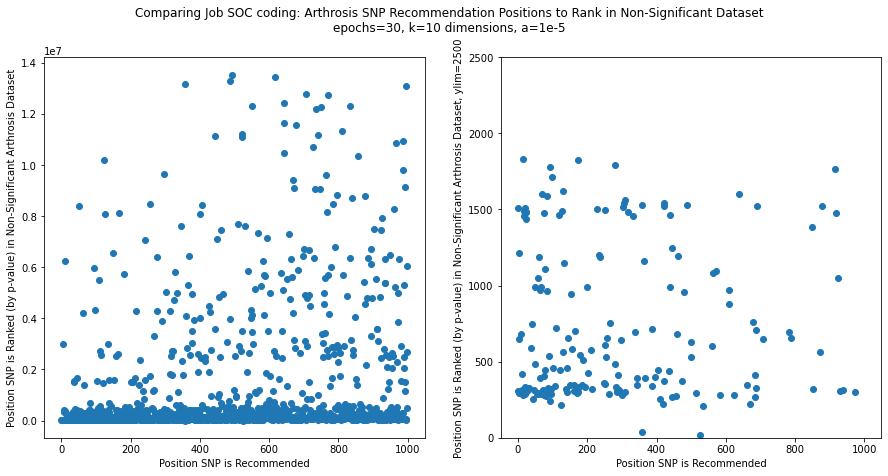

In [303]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15,7))
# fig = plt.figure(figsize=(12, 10))
fig.patch.set_facecolor('white')
ax1.scatter(range(len(non_significant_arthrosis_recs_position[:1000])), non_significant_arthrosis_recs_position[:1000])
ax2.scatter(range(len(non_significant_arthrosis_recs_position[:1000])), non_significant_arthrosis_recs_position[:1000])
ax2.set_ylim(0,2500)

# ax1.set_title('No ylim')
# ax2.set_title('ylim=2500')
ax1.set_xlabel('Position SNP is Recommended')
ax1.set_ylabel('Position SNP is Ranked (by p-value) in Non-Significant Arthrosis Dataset')
ax2.set_xlabel('Position SNP is Recommended')
ax2.set_ylabel('Position SNP is Ranked (by p-value) in Non-Significant Arthrosis Dataset, ylim=2500')
fig.suptitle('Comparing Job SOC coding: Arthrosis SNP Recommendation Positions to Rank in Non-Significant Dataset\nepochs=30, k=10 dimensions, a=1e-5')

**Generating recs for 5 traits and doing cross-full data checks**

In [ ]:
#generating arthrosis recs and comparing against full data for all traits
rec_info_arthrosis = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['#Arthrosis'], print_num=1)
full_data_check_arthrosis_arthrosis = check_full_data(arthrosis_df, rec_info_arthrosis[0][0][:100])
full_data_check_arthrosis_melanoma = check_full_data(melanoma_skin_df, rec_info_arthrosis[0][0][:100])
full_data_check_arthrosis_rheuseropos = check_full_data(rheu_seropos_df, rec_info_arthrosis[0][0][:100])
full_data_check_arthrosis_weight = check_full_data(weight_df, rec_info_arthrosis[0][0][:100])
full_data_check_arthrosis_printers = check_full_data(printers_df, rec_info_arthrosis[0][0][:100])

In [ ]:
#generating melanoma recs and comparing against full data for all traits
rec_info_melanoma = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Malignant melanoma of skin'], print_num=1)
full_data_check_melanoma_arthrosis = check_full_data(arthrosis_df, rec_info_melanoma[0][0][:100])
full_data_check_melanoma_melanoma = check_full_data(melanoma_skin_df, rec_info_melanoma[0][0][:100])
full_data_check_melanoma_rheuseropos = check_full_data(rheu_seropos_df, rec_info_melanoma[0][0][:100])
full_data_check_melanoma_weight = check_full_data(weight_df, rec_info_melanoma[0][0][:100])
full_data_check_melanoma_printers = check_full_data(printers_df, rec_info_melanoma[0][0][:100])

In [ ]:
#generating weight recs and comparing against full data for all traits
rec_info_weight = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Weight'], print_num=1)
full_data_check_weight_arthrosis = check_full_data(arthrosis_df, rec_info_weight[0][0][:100])
full_data_check_weight_melanoma = check_full_data(melanoma_skin_df, rec_info_weight[0][0][:100])
full_data_check_weight_rheuseropos = check_full_data(rheu_seropos_df, rec_info_weight[0][0][:100])
full_data_check_weight_weight = check_full_data(weight_df, rec_info_weight[0][0][:100])
full_data_check_weight_printers = check_full_data(printers_df, rec_info_weight[0][0][:100])

In [ ]:
#generating Seropositive rheumatoid arthritis recs and comparing against full data for all traits
rec_info_sra = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Seropositive rheumatoid arthritis'], print_num=1)
full_data_check_rheuseropos_arthrosis = check_full_data(arthrosis_df, rec_info_sra[0][0][:100])
full_data_check_rheuseropos_melanoma = check_full_data(melanoma_skin_df, rec_info_sra[0][0][:100])
full_data_check_rheuseropos_rheuseropos = check_full_data(rheu_seropos_df, rec_info_sra[0][0][:100])
full_data_check_rheuseropos_weight = check_full_data(weight_df, rec_info_sra[0][0][:100])
full_data_check_rheuseropos_printers = check_full_data(printers_df, rec_info_sra[0][0][:100])

In [ ]:
#generating Job SOC coding: Printers recs and comparing against full data for all traits
rec_info_printers = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Job SOC coding: Printers'], print_num=1)
full_data_check_printers_arthrosis = check_full_data(arthrosis_df, rec_info_printers[0][0][:100])
full_data_check_printers_melanoma = check_full_data(melanoma_skin_df, rec_info_printers[0][0][:100])
full_data_check_printers_rheuseropos = check_full_data(rheu_seropos_df, rec_info_printers[0][0][:100])
full_data_check_printers_weight = check_full_data(weight_df, rec_info_printers[0][0][:100])
full_data_check_printers_printers = check_full_data(printers_df, rec_info_printers[0][0][:100])

In [ ]:
arthrosis_arthrosis_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_arthrosis):
    arthrosis_arthrosis_list.append(float(check[0][4]))
arthrosis_melanoma_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_melanoma):
    arthrosis_melanoma_list.append(float(check[0][4]))
arthrosis_rheuseropos_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_rheuseropos):
    arthrosis_rheuseropos_list.append(float(check[0][4]))
arthrosis_weight_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_weight):
    arthrosis_weight_list.append(float(check[0][4]))
arthrosis_printers_list = []
for data, check in zip(rec_info_arthrosis[0][0], full_data_check_arthrosis_printers):
    arthrosis_printers_list.append(float(check[0][4]))

In [ ]:
melanoma_arthrosis_list = []
for data, check in zip(rec_info_melanoma[0][0], full_data_check_melanoma_arthrosis):
    melanoma_arthrosis_list.append(float(check[0][4]))
melanoma_melanoma_list = []
for data, check in zip(rec_info_melanoma[0][0], full_data_check_melanoma_melanoma):
    melanoma_melanoma_list.append(float(check[0][4]))
melanoma_rheuseropos_list = []
for data, check in zip(rec_info_melanoma[0][0], full_data_check_melanoma_rheuseropos):
    melanoma_rheuseropos_list.append(float(check[0][4]))
melanoma_weight_list = []
for data, check in zip(rec_info_melanoma[0][0], full_data_check_melanoma_weight):
    melanoma_weight_list.append(float(check[0][4]))
melanoma_printers_list = []
for data, check in zip(rec_info_melanoma[0][0], full_data_check_melanoma_printers):
    melanoma_printers_list.append(float(check[0][4]))

In [ ]:
weight_arthrosis_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_arthrosis):
    weight_arthrosis_list.append(float(check[0][4]))
weight_melanoma_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_melanoma):
    weight_melanoma_list.append(float(check[0][4]))
weight_rheuseropos_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_rheuseropos):
    weight_rheuseropos_list.append(float(check[0][4]))
weight_weight_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_weight):
    weight_weight_list.append(float(check[0][4]))
weight_printers_list = []
for data, check in zip(rec_info_weight[0][0], full_data_check_weight_printers):
    weight_printers_list.append(float(check[0][4]))

In [ ]:
rheuseropos_arthrosis_list = []
for data, check in zip(rec_info_sra[0][0], full_data_check_rheuseropos_arthrosis):
    rheuseropos_arthrosis_list.append(float(check[0][4]))
rheuseropos_melanoma_list = []
for data, check in zip(rec_info_sra[0][0], full_data_check_rheuseropos_melanoma):
    rheuseropos_melanoma_list.append(float(check[0][4]))
rheuseropos_rheuseropos_list = []
for data, check in zip(rec_info_sra[0][0], full_data_check_rheuseropos_rheuseropos):
    rheuseropos_rheuseropos_list.append(float(check[0][4]))
rheuseropos_weight_list = []
for data, check in zip(rec_info_sra[0][0], full_data_check_rheuseropos_weight):
    rheuseropos_weight_list.append(float(check[0][4]))
rheuseropos_printers_list = []
for data, check in zip(rec_info_sra[0][0], full_data_check_rheuseropos_printers):
    rheuseropos_printers_list.append(float(check[0][4]))

In [ ]:
printers_arthrosis_list = []
for data, check in zip(rec_info_printers[0][0], full_data_check_printers_arthrosis):
    printers_arthrosis_list.append(float(check[0][4]))
printers_melanoma_list = []
for data, check in zip(rec_info_printers[0][0], full_data_check_printers_melanoma):
    printers_melanoma_list.append(float(check[0][4]))
printers_rheuseropos_list = []
for data, check in zip(rec_info_printers[0][0], full_data_check_printers_rheuseropos):
    printers_rheuseropos_list.append(float(check[0][4]))
printers_weight_list = []
for data, check in zip(rec_info_printers[0][0], full_data_check_printers_weight):
    printers_weight_list.append(float(check[0][4]))
printers_printers_list = []
for data, check in zip(rec_info_printers[0][0], full_data_check_printers_printers):
    printers_printers_list.append(float(check[0][4]))

In [ ]:
print('Average p-value of Arthosis SNP recs to Arthrosis:', sum(arthrosis_list)/len(arthrosis_list))
print('Average p-value of Melanoma SNP recs to Arthrosis:', sum(melanoma_list)/len(melanoma_list))

print('Smallest p-value in Arthrosis SNP recs to Arthrosis:', min(arthrosis_list))
print('Smallest p-value in Melanoma SNP recs to Arthrosis:', min(melanoma_list))

In [34]:
def top_k_ave_p(p_vals):
    not_nan_vals = ~np.isnan(p_vals)
    p_vals = np.array(p_vals)[not_nan_vals]
    averages = []
    for k in range(len(p_vals)):
#         averages.append(np.average(p_vals[:(k+1)]))
        averages.append(sp.stats.mstats.gmean(p_vals[:(k+1)]))
    return averages

top_k_ave_pvals_arthrosis_arthrosis = top_k_ave_p(arthrosis_arthrosis_list)
top_k_ave_pvals_melanoma_arthrosis = top_k_ave_p(melanoma_arthrosis_list)
top_k_ave_pvals_weight_arthrosis = top_k_ave_p(weight_arthrosis_list)
top_k_ave_pvals_rheuseropos_arthrosis = top_k_ave_p(rheuseropos_arthrosis_list)
top_k_ave_pvals_printers_arthrosis = top_k_ave_p(printers_arthrosis_list)

top_k_ave_pvals_arthrosis_melanoma = top_k_ave_p(arthrosis_melanoma_list)
top_k_ave_pvals_melanoma_melanoma = top_k_ave_p(melanoma_melanoma_list)
top_k_ave_pvals_weight_melanoma = top_k_ave_p(weight_melanoma_list)
top_k_ave_pvals_rheuseropos_melanoma = top_k_ave_p(rheuseropos_melanoma_list)
top_k_ave_pvals_printers_melanoma = top_k_ave_p(printers_melanoma_list)

top_k_ave_pvals_arthrosis_weight = top_k_ave_p(arthrosis_weight_list)
top_k_ave_pvals_melanoma_weight = top_k_ave_p(melanoma_weight_list)
top_k_ave_pvals_weight_weight = top_k_ave_p(weight_weight_list)
top_k_ave_pvals_rheuseropos_weight = top_k_ave_p(rheuseropos_weight_list)
top_k_ave_pvals_printers_weight = top_k_ave_p(printers_weight_list)

top_k_ave_pvals_arthrosis_rheuseropos = top_k_ave_p(arthrosis_rheuseropos_list)
top_k_ave_pvals_melanoma_rheuseropos = top_k_ave_p(melanoma_rheuseropos_list)
top_k_ave_pvals_weight_rheuseropos = top_k_ave_p(weight_rheuseropos_list)
top_k_ave_pvals_rheuseropos_rheuseropos = top_k_ave_p(rheuseropos_rheuseropos_list)
top_k_ave_pvals_printers_rheuseropos = top_k_ave_p(printers_rheuseropos_list)

top_k_ave_pvals_arthrosis_printers = top_k_ave_p(arthrosis_printers_list)
top_k_ave_pvals_melanoma_printers = top_k_ave_p(melanoma_printers_list)
top_k_ave_pvals_weight_printers = top_k_ave_p(weight_printers_list)
top_k_ave_pvals_rheuseropos_printers = top_k_ave_p(rheuseropos_printers_list)
top_k_ave_pvals_printers_printers = top_k_ave_p(printers_printers_list)

In [ ]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_melanoma_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_weight_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_rheuseropos_arthrosis)
plt.plot(range(1, 101), top_k_ave_pvals_printers_arthrosis)

plt.legend(['Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Different Traits to Arthrosis')

In [ ]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_melanoma)
plt.plot(range(1, 101), top_k_ave_pvals_melanoma_melanoma)
plt.plot(range(1, 101), top_k_ave_pvals_weight_melanoma)
plt.plot(range(1, 101), top_k_ave_pvals_rheuseropos_melanoma)
plt.plot(range(1, 101), top_k_ave_pvals_printers_melanoma)

plt.legend(['Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Different Traits to Malignant Melanoma of Skin')

In [ ]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_weight)
plt.plot(range(1, 101), top_k_ave_pvals_melanoma_weight)
plt.plot(range(1, 101), top_k_ave_pvals_weight_weight)
plt.plot(range(1, 101), top_k_ave_pvals_rheuseropos_weight)
plt.plot(range(1, 101), top_k_ave_pvals_printers_weight)

plt.legend(['Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Different Traits to Weight')

In [ ]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_rheuseropos)
plt.plot(range(1, 101), top_k_ave_pvals_melanoma_rheuseropos)
plt.plot(range(1, 101), top_k_ave_pvals_weight_rheuseropos)
plt.plot(range(1, 101), top_k_ave_pvals_rheuseropos_rheuseropos)
plt.plot(range(1, 101), top_k_ave_pvals_printers_rheuseropos)

plt.legend(['Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Different Traits to Seropositive Rheumatoid Arthritis')

In [ ]:
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor('white')
plt.yscale('log')
plt.plot(range(1, 101), top_k_ave_pvals_arthrosis_printers)
plt.plot(range(1, 97), top_k_ave_pvals_melanoma_printers)
plt.plot(range(1, 101), top_k_ave_pvals_weight_printers)
plt.plot(range(1, 100), top_k_ave_pvals_rheuseropos_printers)
plt.plot(range(1, 101), top_k_ave_pvals_printers_printers)

plt.legend(['Arthrosis', 'Malignant melanoma of skin', 'Weight', 'Seropositive rheumatoid arthritis', 'Job SOC coding: Printers'], loc='lower right')
plt.xlabel('k')
plt.ylabel('Average p-value (Geometric Mean)')
plt.title('Average p-value of Top k Recommended SNPs for Different Traits to Job SOC coding: Printers')

**Generating SNP recs for Traits in Figure 4c of DHS paper and saving as bed files**

In [ ]:
trait_codes_df[trait_codes_df['description'].str.contains('unsuccessful')]

In [23]:
traits = []
# traits.append('Gap coding: Full-time or part-time education')
traits.append('Non-cancer illness code, self-reported: systemic lupus erythematosis/sle')
traits.append('Mean corpuscular haemoglobin concentration')
traits.append('QRS duration')
traits.append('Corneal hysteresis (left)')
# traits.append('Number of full sisters')
traits.append('Number of unsuccessful stop-smoking attempts')
traits.append('Diagnoses - main ICD10: N81 Female genital prolapse')
traits.append('Illnesses of father: Chronic bronchitis/emphysema')
traits.append('Reticulocyte count')
traits.append('Pulse rate, automated reading')

In [24]:
print(traits)

['Non-cancer illness code, self-reported: systemic lupus erythematosis/sle', 'Mean corpuscular haemoglobin concentration', 'QRS duration', 'Corneal hysteresis (left)', 'Number of unsuccessful stop-smoking attempts', 'Diagnoses - main ICD10: N81 Female genital prolapse', 'Illnesses of father: Chronic bronchitis/emphysema', 'Reticulocyte count', 'Pulse rate, automated reading']


In [25]:
trait_names_4c = ['lupus', 'mean_corpuscular_haemoglobin_concentration', 'QRS_duration', 'Corneal_hysteresis_left', 'unsuccessful_stop_smoking_attempts', 'female_genital_prolapse', 'father_chronic_bronchitis_emphysema', 'reticulocyte_count', 'pulse_rate_automated_reading']

In [26]:
pickle_in = open('/home/ctrader/Hold/GWAS/pickled_models_afo_alpha_epochs_dimensions/GWAS_model_e30_d20_reg1e-05_lr01_CT20211130.pickle', 'rb')
model_e30_d20_reg00001_lr01_CT20211130=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/GWAS/pickled_models_afo_alpha_epochs_dimensions/gwas_data_for_training_CT20211130.pickle', 'rb')
gwas_data_for_training_CT20211130=pickle.load(pickle_in)

In [27]:
#trait recs for model_e30_d20_reg0005_lr01 
rec_info_4c_top_traits = sample_recommendation(model_e30_d20_reg00001_lr01_CT20211130, gwas_data_for_training_CT20211130, traits, print_num=1)

Disease: Non-cancer illness code, self-reported: systemic lupus erythematosis/sle (2543)
   Known Positives (4100):
      Reference SNP cluster ID: rs148297150, chr2:26313027-26313028, p-value = 1.00162e-191
      ...

   Recommended:
      Reference SNP cluster ID: rs9272426, chr6:32637412-32637413
Disease: Mean corpuscular haemoglobin concentration (2160)
   Known Positives (26368):
      Reference SNP cluster ID: rs116615990, chr16:30084966-30084967, p-value = 2.66651e-305
      ...

   Recommended:
      Reference SNP cluster ID: rs562289, chr6:32609269-32609270
Disease: QRS duration (2805)
   Known Positives (361):
      Reference SNP cluster ID: rs183155578, chr19:17206250-17206251, p-value = 1.71093e-35
      ...

   Recommended:
      Reference SNP cluster ID: rs556642707, chr16:67660381-67660382
Disease: Corneal hysteresis (left) (317)
   Known Positives (5046):
      Reference SNP cluster ID: rs113265906, chr16:57756026-57756027, p-value = 8.10853e-168
      ...

   Recommend

In [28]:
cols = ['reference snp cluster ID', 'chr', 'start', 'end', 'pred score']

In [31]:
lupus_recs_df = pd.DataFrame(rec_info_4c_top_traits[0][0], columns = ['reference snp cluster ID'])
mean_corpuscular_haemoglobin_concentration_recs_df = pd.DataFrame(rec_info_4c_top_traits[1][0], columns = ['reference snp cluster ID'])
QRS_duration_recs_df = pd.DataFrame(rec_info_4c_top_traits[2][0], columns = ['reference snp cluster ID'])
Corneal_hysteresis_left_recs_df = pd.DataFrame(rec_info_4c_top_traits[3][0], columns = ['reference snp cluster ID'])
unsuccessful_stop_smoking_attempts_recs_df = pd.DataFrame(rec_info_4c_top_traits[4][0], columns = ['reference snp cluster ID'])
female_genital_prolapse_recs_df = pd.DataFrame(rec_info_4c_top_traits[5][0], columns = ['reference snp cluster ID'])
father_chronic_bronchitis_emphysema_recs_df = pd.DataFrame(rec_info_4c_top_traits[6][0], columns = ['reference snp cluster ID'])
reticulocyte_count_recs_df = pd.DataFrame(rec_info_4c_top_traits[7][0], columns = ['reference snp cluster ID'])
pulse_rate_automated_reading_recs_df = pd.DataFrame(rec_info_4c_top_traits[8][0], columns = ['reference snp cluster ID'])

In [32]:
#merging dataframes together to compare snp ranks for each trait
lupus_recs_df['lupus rank'] = lupus_recs_df.index
mean_corpuscular_haemoglobin_concentration_recs_df['mchc rank'] = mean_corpuscular_haemoglobin_concentration_recs_df.index
QRS_duration_recs_df['QRS rank'] = QRS_duration_recs_df.index
Corneal_hysteresis_left_recs_df['corneal hysteresis rank'] = Corneal_hysteresis_left_recs_df.index
unsuccessful_stop_smoking_attempts_recs_df['stop smoking rank'] = unsuccessful_stop_smoking_attempts_recs_df.index
female_genital_prolapse_recs_df['genital prolapse rank'] = female_genital_prolapse_recs_df.index
father_chronic_bronchitis_emphysema_recs_df['chronic bronchitis rank'] = father_chronic_bronchitis_emphysema_recs_df.index
reticulocyte_count_recs_df['reticulocyte count rank'] = reticulocyte_count_recs_df.index
pulse_rate_automated_reading_recs_df['pulse rate rank'] = pulse_rate_automated_reading_recs_df.index

merged_df = lupus_recs_df.merge(mean_corpuscular_haemoglobin_concentration_recs_df[['reference snp cluster ID', 'mchc rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(QRS_duration_recs_df[['reference snp cluster ID', 'QRS rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(Corneal_hysteresis_left_recs_df[['reference snp cluster ID', 'corneal hysteresis rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(unsuccessful_stop_smoking_attempts_recs_df[['reference snp cluster ID', 'stop smoking rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(female_genital_prolapse_recs_df[['reference snp cluster ID', 'genital prolapse rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(father_chronic_bronchitis_emphysema_recs_df[['reference snp cluster ID', 'chronic bronchitis rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(reticulocyte_count_recs_df[['reference snp cluster ID', 'reticulocyte count rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')
merged_df = merged_df.merge(pulse_rate_automated_reading_recs_df[['reference snp cluster ID', 'pulse rate rank']], left_on='reference snp cluster ID', right_on='reference snp cluster ID')

In [33]:
merged_df['ranks averaged'] = (merged_df['lupus rank'] + merged_df['mchc rank'] + merged_df['QRS rank'] + merged_df['corneal hysteresis rank'] + merged_df['stop smoking rank'] + merged_df['genital prolapse rank'] + merged_df['chronic bronchitis rank'] + merged_df['reticulocyte count rank'] + merged_df['pulse rate rank'])/9
ranks_averaged_list = list(merged_df['ranks averaged'])
lupus_ranks = list(merged_df['lupus rank'])
merged_df.head()

,reference snp cluster ID,lupus rank,mchc rank,QRS rank,corneal hysteresis rank,stop smoking rank,genital prolapse rank,chronic bronchitis rank,reticulocyte count rank,pulse rate rank,ranks averaged
0,rs9275426,789,7326,2009900,1877067,13047,1845768,1542,31183,2028919,868393.444444
1,rs9275422,878,8145,1980114,2062789,15707,1773845,3208,41624,2026279,879176.555556
2,rs9275442,895,13829,2005932,1950046,12964,1829154,1813,50831,2032724,877576.444444
3,rs56051108,954,8164,2030169,1971316,12658,1922989,2963,43426,2006271,888767.777778
4,rs71565338,978,11529,1933235,2016347,28091,1437184,1468,63845,2046874,837727.888889


Text(0.5, 1.0, 'Comparing SNP Recommendation Rankings from 9 Traits from Extended Data Fig. 9a and 9d of DHS Paper\nepochs=30, k=20 components, alpha=1e-5, learning rate=0.01')

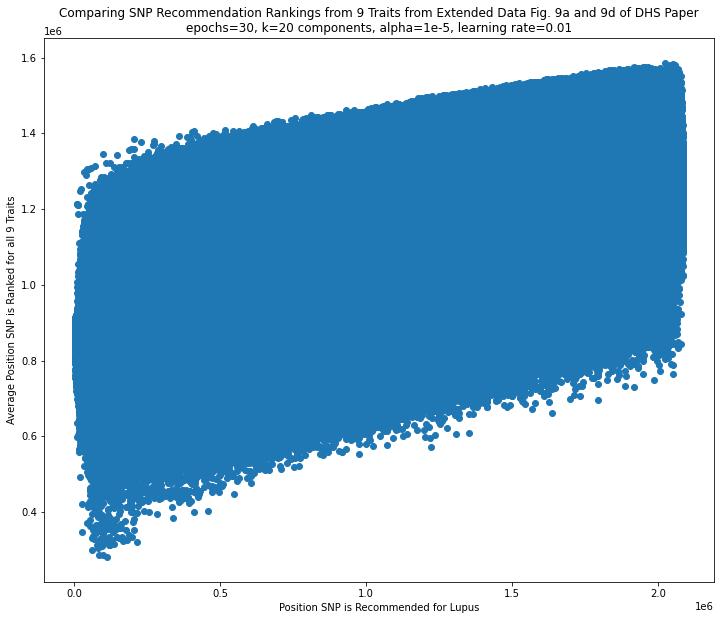

In [34]:
fig = plt.figure(figsize=(12, 10))
fig.patch.set_facecolor('white')
plt.scatter(lupus_ranks, ranks_averaged_list)

plt.xlabel('Position SNP is Recommended for Lupus')
plt.ylabel('Average Position SNP is Ranked for all 9 Traits')
plt.title('Comparing SNP Recommendation Rankings from 9 Traits from Extended Data Fig. 9a and 9d of DHS Paper\nepochs=30, k=20 components, alpha=1e-5, learning rate=0.01')

In [87]:
trait_b, trait_e = model_e30_d20_reg0005_lr01.get_user_representations()
snp_b, snp_e = model_e30_d20_reg0005_lr01.get_item_representations()

In [88]:
trait_e

array([[ 1.04482081e-19,  4.81603067e-20, -1.21061010e-19, ...,
        -1.69186857e-19, -1.08570415e-19,  5.71507939e-20],
       [ 2.21226240e-20,  4.84902904e-20, -9.52965865e-21, ...,
         5.49887247e-20, -2.67631823e-21,  3.52998002e-20],
       [-3.16523440e-20,  8.98788216e-20,  2.32316567e-20, ...,
        -1.08067774e-19,  9.87704219e-21, -8.41507575e-20],
       ...,
       [-4.16110138e-20, -3.39998503e-20,  2.38953712e-19, ...,
         1.17286521e-19,  2.45639089e-19,  9.34969920e-21],
       [-8.68527688e-21, -7.44556837e-20, -1.09582351e-20, ...,
         6.14055460e-20,  5.22519298e-20, -4.40650357e-20],
       [-1.76181858e-19,  1.68596844e-19,  1.85140198e-19, ...,
        -1.41885773e-20, -5.38055171e-20, -2.44422905e-20]], dtype=float32)

In [89]:
snp_e

array([[-3.65214561e-19, -8.44882795e-19, -1.72968119e-19, ...,
         2.45590286e-19, -2.65970724e-19,  2.61968772e-19],
       [ 3.68358713e-20,  2.44079776e-19,  6.19454623e-19, ...,
        -3.33946837e-20,  2.27103626e-19,  2.91092535e-19],
       [-9.94174730e-19, -1.01144936e-18, -1.13954759e-18, ...,
        -6.33162427e-20, -1.13232175e-18, -1.20963022e-17],
       ...,
       [-2.75392879e-19,  1.87311586e-19, -2.05738895e-19, ...,
         2.83460941e-19, -2.18746440e-19,  3.55738819e-19],
       [ 1.93776532e-19,  2.89401778e-19, -6.25382096e-19, ...,
         1.55304938e-18,  5.19027142e-20, -2.20135508e-18],
       [ 1.04365223e-19, -1.04254503e-19,  2.76924495e-20, ...,
        -5.59944665e-20,  3.84644827e-19,  5.61443929e-19]], dtype=float32)

In [29]:
today = date.today()
for j in range(len(traits)):
    pickle_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d20_reg1e-05_lr01_rec_info_' + trait_names_4c[j] + '_CT' + today.strftime("%Y%m%d") + '.pickle')
    pickle_out = open(pickle_path_name, 'wb')
    pickle.dump(rec_info_4c_top_traits[j], pickle_out)
    pickle_out.close()

In [30]:
today = date.today()
for j in range(len(traits)):
    bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d20_reg1e-05_lr01_rec_info_' + trait_names_4c[j] + '_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(len(rec_info_4c_top_traits[j][1])):
        f.write(rec_info_4c_top_traits[j][1][i] + '\t' + str(rec_info_4c_top_traits[j][2][i]) + '\t' + str(rec_info_4c_top_traits[j][3][i]) + '\t' + str(rec_info_4c_top_traits[j][4][i]) + '\t' + str(rec_info_4c_top_traits[j][0][i]) + '\n')
    f.close()

In [77]:
rec_info_4c_top_traits = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, traits, print_num=1)

Disease: Non-cancer illness code, self-reported: systemic lupus erythematosis/sle (2543)
   Known Positives (4100):
      Reference SNP cluster ID: rs148297150, chr2:26313027-26313028, p-value = 1.00162e-191
      ...

   Recommended:
      Reference SNP cluster ID: rs9273367, chr6:32658661-32658662
Disease: Mean corpuscular haemoglobin concentration (2160)
   Known Positives (26368):
      Reference SNP cluster ID: rs116615990, chr16:30084966-30084967, p-value = 2.66651e-305
      ...

   Recommended:
      Reference SNP cluster ID: rs35186928, chr6:32614827-32614828
Disease: QRS duration (2805)
   Known Positives (361):
      Reference SNP cluster ID: rs183155578, chr19:17206250-17206251, p-value = 1.71093e-35
      ...

   Recommended:
      Reference SNP cluster ID: rs58107700, chr7:6621598-6621599
Disease: Corneal hysteresis (left) (317)
   Known Positives (5046):
      Reference SNP cluster ID: rs113265906, chr16:57756026-57756027, p-value = 8.10853e-168
      ...

   Recommended

In [ ]:
traits = []
traits.append('Reticulocyte count')
traits.append('Pulse rate, automated reading')

In [ ]:
trait_names_4c_rc_prar = ['reticulocyte_count', 'pulse_rate_automated_reading']

In [ ]:
rec_info_4c_rc_prar = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, traits, print_num=1)

In [ ]:
today = date.today()
for j in range(len(traits)):
    bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_rec_info_' + trait_names_4c_rc_prar[j] + '_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(len(rec_info_4c_rc_prar[j][1])):
        f.write(rec_info_4c_rc_prar[j][1][i] + '\t' + str(rec_info_4c_rc_prar[j][2][i]) + '\t' + str(rec_info_4c_rc_prar[j][3][i]) + '\t' + str(rec_info_4c_rc_prar[j][4][i]) + '\t' + str(rec_info_4c_rc_prar[j][0][i]) + '\n')
    f.close()

In [ ]:
#generating recs from first model
traits = ['Non-cancer illness code, self-reported: systemic lupus erythematosis/sle', 'Mean corpuscular haemoglobin concentration']
rec_info_4c_lupus_mchc = sample_recommendation(gwas_model_e30_d10, gwas_data_e30_d10, traits, print_num=1)

In [ ]:
trait_names_lupus_mchc = ['lupus', 'mean_corpuscular_haemoglobin_concentration']

In [ ]:
today = date.today()
for j in range(len(traits)):
    bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_rec_info_' + trait_names_lupus_mchc[j] + '_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(len(rec_info_4c_lupus_mchc[j][1])):
        f.write(rec_info_4c_lupus_mchc[j][1][i] + '\t' + str(rec_info_4c_lupus_mchc[j][2][i]) + '\t' + str(rec_info_4c_lupus_mchc[j][3][i]) + '\t' + str(rec_info_4c_lupus_mchc[j][4][i]) + '\t' + str(rec_info_4c_lupus_mchc[j][0][i]) + '\n')
    f.close()

In [ ]:
len(rec_info_4c_top_traits[0])

In [ ]:
today = date.today()
for j in range(len(traits)):
    pickle_path_name = os.path.join('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/GWAS/recommendations/', 'GWAS_rec_info_' + trait_names_4c[j] + '_CT' + today.strftime("%Y%m%d") + '.pickle')
    pickle_out = open(pickle_path_name, 'wb')
    pickle.dump(rec_info_4c_top_traits[j], pickle_out)
    pickle_out.close()

In [ ]:
today = date.today()
for j in range(len(traits)):
    bed_path_name = os.path.join('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/GWAS/recommendations/', 'GWAS_rec_info_' + trait_names_4c[j] + '_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(len(rec_info_4c_top_traits[j][1])):
        f.write(rec_info_4c_top_traits[j][1][i] + '\t' + str(rec_info_4c_top_traits[j][2][i]) + '\t' + str(rec_info_4c_top_traits[j][3][i]) + '\t' + str(rec_info_4c_top_traits[j][4][i]) + '\t' + str(rec_info_4c_top_traits[j][0][i]) + '\n')
    f.close()

In [ ]:
rec_info_CONGEN_HEART_ARTER = sample_recommendation(gwas_model_e30_d10_reg00001, data_e30_d10_reg00001, ['Congenital malformations of heart and great arteries'], print_num=1)
# pickle_out = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/GWAS/recommendations/GWAS_rec_info_CONGEN_HEART_ARTER_CT20211117.pickle', 'wb')
# pickle.dump(rec_info_CONGEN_HEART_ARTER, pickle_out)
# pickle_out.close()

In [ ]:
bed_path_name = os.path.join('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/GWAS/recommendations/', 'GWAS_rec_info_CONGEN_HEART_ARTER_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(rec_info_CONGEN_HEART_ARTER[0][1])):
    f.write(rec_info_CONGEN_HEART_ARTER[0][1][i] + '\t' + str(rec_info_CONGEN_HEART_ARTER[0][2][i]) + '\t' + str(rec_info_CONGEN_HEART_ARTER[0][3][i]) + '\t' + str(rec_info_CONGEN_HEART_ARTER[0][4][i]) + '\t' + str(rec_info_CONGEN_HEART_ARTER[0][0][i]) + '\n')
f.close()

**Gathering data for Iceberg plots for "Non-cancer illness code, self-reported: systemic lupus erythematosis/sle"**

In [ ]:
trait = 'Non-cancer illness code, self-reported: systemic lupus erythematosis/sle'
trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]
#genes known to relate to the disease
known_ranked_df = ts[(ts['Trait']==trait)].sort_values('pval_mlog', ascending=False)
known_ranked = list(known_ranked_df['snp_ind'])

In [ ]:
ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
df_first = df[df['Trait']==trait]
df_first = df_first.groupby(by=['Reference SNP cluster ID']).first()
known_s = list(ts_first.loc[known_ranked]['Reference SNP cluster ID'])
known_chrom = list(df_first.loc[known_s]['Chromosome'])
known_p1 = list(df_first.loc[known_s]['p1'])
known_p2 = list(df_first.loc[known_s]['p2'])
known_pval = list(df_first.loc[known_s]['p-value'])
known_pval_np = np.array(known_pval)
known_pval_mlog = list(-np.log(list(map(float, known_pval_np))))

In [ ]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_known_positives_lupus_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(known_pval)):
    f.write(known_chrom[i] + '\t' + str(known_p1[i]) + '\t' + str(known_p2[i]) + '\t' + str(known_pval[i]) + '\t' + str(known_s[i]) + '\t' + str(known_pval_mlog[i]) + '\n')
f.close()

In [ ]:
lupus_full_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/20002_1381.gwas.imputed_v3.both_sexes/20002_1381.hg38.bed.gz','r') as f:        
    for line in f:        
        lupus_full_data.append(line.decode("utf-8").strip('\n').split('\t'))
lupus_full_df = pd.DataFrame(lupus_full_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

In [ ]:
lupus_full_df['pval_mlog'] = -np.log(list(map(float, list(lupus_full_df['p-value']))))

In [ ]:
lupus_full_df = lupus_full_df.sort_values(by=['pval_mlog'], ascending=False)
lupus_full_df = lupus_full_df.dropna(subset=['pval_mlog'])
lupus_full_df = lupus_full_df[lupus_full_df['pval_mlog']<(-np.log(5e-8))]
lupus_full_df

In [ ]:
lupus_full_s = list(lupus_full_df['Reference SNP cluster ID'])
lupus_full_chrm = list(lupus_full_df['Chromosome'])
lupus_full_start = list(lupus_full_df['Start'])
lupus_full_end = list(lupus_full_df['End'])
lupus_full_pval = list(lupus_full_df['p-value'])
lupus_full_pval_mlog = list(lupus_full_df['pval_mlog'])

In [ ]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_full_data_lupus_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(lupus_full_pval)):
    f.write(lupus_full_chrm[i] + '\t' + str(lupus_full_start[i]) + '\t' + str(lupus_full_end[i]) + '\t' + str(lupus_full_pval[i]) + '\t' + str(lupus_full_s[i]) + '\t' + str(lupus_full_pval_mlog[i]) + '\n')
f.close()

**Gathering data for Iceberg plots for "Mean corpuscular haemoglobin concentration"**

In [ ]:
trait = 'Mean corpuscular haemoglobin concentration'
trait_ind = ts[ts['Trait'] == trait]['trait_ind'].tolist()[0]
#genes known to relate to the disease
known_ranked_df = ts[(ts['Trait']==trait)].sort_values('pval_mlog', ascending=False)
known_ranked = list(known_ranked_df['snp_ind'])

In [ ]:
ts_first = ts.groupby(by=['snp_ind']).first().reset_index()
df_first = df[df['Trait']==trait]
df_first = df_first.groupby(by=['Reference SNP cluster ID']).first()
known_s = list(ts_first.loc[known_ranked]['Reference SNP cluster ID'])
known_chrom = list(df_first.loc[known_s]['Chromosome'])
known_p1 = list(df_first.loc[known_s]['p1'])
known_p2 = list(df_first.loc[known_s]['p2'])
known_pval = list(df_first.loc[known_s]['p-value'])
known_pval_np = np.array(known_pval)
known_pval_mlog = list(-np.log(list(map(float, known_pval_np))))

In [ ]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_known_positives_mean_corpuscular_haemoglobin_concentration_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(known_pval)):
    f.write(known_chrom[i] + '\t' + str(known_p1[i]) + '\t' + str(known_p2[i]) + '\t' + str(known_pval[i]) + '\t' + str(known_s[i]) + '\t' + str(known_pval_mlog[i]) + '\n')
f.close()

In [ ]:
mean_corpuscular_haemoglobin_concentration_full_data = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/phenotypes/30060_irnt.gwas.imputed_v3.both_sexes/30060_irnt.hg38.bed.gz','r') as f:        
    for line in f:        
        mean_corpuscular_haemoglobin_concentration_full_data.append(line.decode("utf-8").strip('\n').split('\t'))
mean_corpuscular_haemoglobin_concentration_full_df = pd.DataFrame(mean_corpuscular_haemoglobin_concentration_full_data, columns=['Chromosome', 'Start', 'End', 'Reference SNP cluster ID', 'p-value'])

In [ ]:
mean_corpuscular_haemoglobin_concentration_full_df['pval_mlog'] = -np.log(list(map(float, list(mean_corpuscular_haemoglobin_concentration_full_df['p-value']))))

In [ ]:
mean_corpuscular_haemoglobin_concentration_full_df = mean_corpuscular_haemoglobin_concentration_full_df.sort_values(by=['pval_mlog'], ascending=False)
mean_corpuscular_haemoglobin_concentration_full_df = mean_corpuscular_haemoglobin_concentration_full_df.dropna(subset=['pval_mlog'])
mean_corpuscular_haemoglobin_concentration_full_df = mean_corpuscular_haemoglobin_concentration_full_df[mean_corpuscular_haemoglobin_concentration_full_df['pval_mlog']<(-np.log(5e-8))]
mean_corpuscular_haemoglobin_concentration_full_df

In [ ]:
mean_corpuscular_haemoglobin_concentration_full_s = list(mean_corpuscular_haemoglobin_concentration_full_df['Reference SNP cluster ID'])
mean_corpuscular_haemoglobin_concentration_full_chrm = list(mean_corpuscular_haemoglobin_concentration_full_df['Chromosome'])
mean_corpuscular_haemoglobin_concentration_full_start = list(mean_corpuscular_haemoglobin_concentration_full_df['Start'])
mean_corpuscular_haemoglobin_concentration_full_end = list(mean_corpuscular_haemoglobin_concentration_full_df['End'])
mean_corpuscular_haemoglobin_concentration_full_pval = list(mean_corpuscular_haemoglobin_concentration_full_df['p-value'])
mean_corpuscular_haemoglobin_concentration_full_pval_mlog = list(mean_corpuscular_haemoglobin_concentration_full_df['pval_mlog'])

In [ ]:
today = date.today()
bed_path_name = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_full_data_mean_corpuscular_haemoglobin_concentration_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(len(mean_corpuscular_haemoglobin_concentration_full_pval)):
    f.write(mean_corpuscular_haemoglobin_concentration_full_chrm[i] + '\t' + str(mean_corpuscular_haemoglobin_concentration_full_start[i]) + '\t' + str(mean_corpuscular_haemoglobin_concentration_full_end[i]) + '\t' + str(mean_corpuscular_haemoglobin_concentration_full_pval[i]) + '\t' + str(mean_corpuscular_haemoglobin_concentration_full_s[i]) + '\t' + str(mean_corpuscular_haemoglobin_concentration_full_pval_mlog[i]) + '\n')
f.close()